---
title: Introduction to Transformers
author: Mark Fuge
date: November 25, 2025
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

Thus far, most of the models we have been using have assumed either a list of scalars or, in some cases, a set of convolutions on a regular grid, and both of these have assumed a certain fixed size (*i.e.*, length) of the data. However, engineering data often comes instead as a set of points/measurements of possibly arbitrary size/length rather than as a fixed list of numbers. For example, you might have a laser scan of a part, the nodes of an unstructured mesh, or the locations of multiple sensors on a structure. Such a set has no natural order, and two different parts can differ in the number of measurements they have. This chapter introduces *attention*, the building block of transformers, and builds it up on simple 2D and 3D point sets, where we can plot what the model does.

## Learning Objectives
By the end of this chapter, you should be able to:

- Explain why flattening a point set makes an MLP depend on the order and the number of points, and how pooling makes a set model independent of both.
- Compute scaled dot-product attention for a small set of points, and explain what the queries, the keys, the values and the weights $a_{ij}$ each do.
- Explain how the size of the scores moves attention between an average over all points and a lookup of one point.
- Explain the key difference between PointNet and attention.
- Estimate how the cost of attention grows with the number of points, and recognize situations where that cost is worth paying, and when it is not.

In [83]:
import math
import random
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objs as go
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
from plotly.offline import init_notebook_mode
from torch.utils.data import DataLoader, Dataset, random_split

init_notebook_mode(connected=True)
plt.style.use("seaborn-v0_8")
torch.set_float32_matmul_precision("high")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

def to_device(batch: Dict[str, torch.Tensor], device: torch.device) -> Dict[str, torch.Tensor]:
    return {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}

In [84]:
def default_forward(model: nn.Module, batch: Dict[str, torch.Tensor], device: torch.device) -> torch.Tensor:
    return model(batch["inputs"].to(device))

def train_classifier(
    model: nn.Module,
    train_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: Callable[[torch.Tensor, torch.Tensor], torch.Tensor],
    epochs: int,
    *,
    device: torch.device = DEVICE,
    forward_fn: Optional[Callable[[nn.Module, Dict[str, torch.Tensor], torch.device], torch.Tensor]] = None,
    val_loader: Optional[DataLoader] = None,
) -> Dict[str, List[float]]:
    history: Dict[str, List[float]] = {"train_loss": [], "train_acc": []}
    if val_loader is not None:
        history.update({"val_loss": [], "val_acc": []})

    forward = forward_fn or default_forward
    model.to(device)

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for batch in train_loader:
            optimizer.zero_grad()
            logits = forward(model, batch, device)
            if isinstance(logits, tuple):
                logits = logits[0]
            labels = batch["labels"].to(device)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            preds = torch.argmax(logits, dim=-1)
            running_correct += (preds == labels).sum().item()
            running_total += labels.size(0)

        history["train_loss"].append(running_loss / running_total)
        history["train_acc"].append(running_correct / running_total)

        if val_loader is not None:
            val_metrics = evaluate_classifier(model, val_loader, criterion, forward_fn=forward, device=device)
            history["val_loss"].append(val_metrics["loss"])
            history["val_acc"].append(val_metrics["acc"])

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train_loss={history['train_loss'][-1]:.4f} train_acc={history['train_acc'][-1]:.3f}"
            + (
                f" | val_loss={history['val_loss'][-1]:.4f} val_acc={history['val_acc'][-1]:.3f}" if val_loader is not None else ""
            )
        )

    return history

def evaluate_classifier(
    model: nn.Module,
    data_loader: DataLoader,
    criterion: Optional[Callable[[torch.Tensor, torch.Tensor], torch.Tensor]] = None,
    *,
    device: torch.device = DEVICE,
    forward_fn: Optional[Callable[[nn.Module, Dict[str, torch.Tensor], torch.device], torch.Tensor]] = None,
) -> Dict[str, np.ndarray]:
    forward = forward_fn or default_forward
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    preds_list: List[torch.Tensor] = []
    labels_list: List[torch.Tensor] = []

    with torch.no_grad():
        for batch in data_loader:
            logits = forward(model, batch, device)
            if isinstance(logits, tuple):
                logits = logits[0]
            labels = batch["labels"].to(device)
            if criterion is not None:
                loss = criterion(logits, labels)
                total_loss += loss.item() * labels.size(0)
            predictions = torch.argmax(logits, dim=-1)
            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)
            preds_list.append(predictions.cpu())
            labels_list.append(labels.cpu())

    preds_tensor = torch.cat(preds_list)
    labels_tensor = torch.cat(labels_list)
    metrics = {
        "loss": (total_loss / total_samples) if criterion is not None else math.nan,
        "acc": total_correct / total_samples,
        "preds": preds_tensor.numpy(),
        "labels": labels_tensor.numpy(),
    }
    return metrics

In [85]:
def plot_history(history: Dict[str, List[float]], title: str) -> None:
    if not history:
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train")
    if "val_loss" in history:
        axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title(f"Loss | {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-Entropy")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")
    if "val_acc" in history:
        axes[1].plot(history["val_acc"], label="val")
    axes[1].set_title(f"Accuracy | {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1.05)
    axes[1].legend()
    plt.tight_layout()


def plot_confusion(cm: np.ndarray, class_names: List[str], title: str) -> None:
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()


def scatter_2d_points(points: np.ndarray, label: str, ax: Optional[plt.Axes] = None, colors: Optional[np.ndarray] = None) -> None:
    if ax is None:
        ax = plt.gca()
    if colors is None:
        ax.scatter(points[:, 0], points[:, 1], s=10, alpha=0.8)
    else:
        sc = ax.scatter(points[:, 0], points[:, 1], c=colors, cmap="viridis", s=10)
        plt.colorbar(sc, ax=ax, fraction=0.046)
    ax.set_aspect("equal")
    ax.set_title(label)


def scatter_3d_points(points: np.ndarray, label: str, colors: Optional[np.ndarray] = None, interactive: bool = False) -> None:
    """3D scatter with optional interactive Plotly backend.

    Parameters
    ----------
    points : (N,3) array
        Point coordinates.
    label : str
        Title for the plot.
    colors : (N,) array, optional
        Scalar weights for coloring points.
    interactive : bool
        If True, render an interactive Plotly plot; otherwise use Matplotlib.
    """
    if interactive:
        if colors is None:
            colors = np.zeros(points.shape[0])
        trace = go.Scatter3d(
            x=points[:, 0],
            y=points[:, 1],
            z=points[:, 2],
            mode="markers",
            marker=dict(size=2, color=colors, colorscale="Viridis", opacity=0.8),
        )
        layout = go.Layout(title=label, scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z"), height=500)
        fig = go.Figure(data=[trace], layout=layout)
        fig.show()
    else:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
        if colors is None:
            ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=5, alpha=0.8)
        else:
            sc = ax.scatter(points[:, 0], points[:, 1], points[:, 2], c=colors, cmap="inferno", s=8)
            fig.colorbar(sc, ax=ax, shrink=0.6)
        ax.set_title(label)
        plt.tight_layout()


def plot_metric_curve(df: pd.DataFrame, title: str, hue: str = "model") -> None:
    plt.figure(figsize=(6, 4))
    sns.lineplot(data=df, x="noise", y="accuracy", hue=hue, marker="o")
    plt.title(title)
    plt.ylabel("Accuracy")
    plt.xlabel("Noise std")
    plt.ylim(0, 1.05)
    plt.tight_layout()

def plot_attention_overlay(points: np.ndarray, weights: np.ndarray, title: str) -> None:
    norm_weights = (weights - weights.min()) / (weights.max() - weights.min() + 1e-8)
    scatter_2d_points(points, title + "\n(colors rescaled to [0, 1])", colors=norm_weights)

def visualize_embeddings(embeddings: np.ndarray, labels: np.ndarray, class_names: List[str], title: str, method: str = "pca", dim=2) -> None:
    reducer = PCA(n_components=dim) if method.lower() == "pca" else TSNE(n_components=dim, perplexity=30, learning_rate="auto")
    reduced = reducer.fit_transform(embeddings)
    # If dim == 3, use plotly for an interactive plot
    if dim == 3:
        # Create separate traces for each class to get proper legend
        traces = []
        unique_labels = np.unique(labels)
        for label_idx in unique_labels:
            mask = labels == label_idx
            trace = go.Scatter3d(
                x=reduced[mask, 0],
                y=reduced[mask, 1],
                z=reduced[mask, 2],
                mode="markers",
                name=class_names[label_idx],
                marker=dict(size=3, opacity=0.7),
            )
            traces.append(trace)
        layout = go.Layout(
            title=f"{title} ({method.upper()})",
            scene=dict(xaxis_title="Component 1", yaxis_title="Component 2", zaxis_title="Component 3"),
            height=600,
            showlegend=True,
        )
        fig = go.Figure(data=traces, layout=layout)
        fig.show()
        return
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x=reduced[:, 0], y=reduced[:, 1], hue=[class_names[i] for i in labels], s=15, palette="deep", alpha=0.8)
    plt.title(f"{title} ({method.upper()})")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.legend(title="Class", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()

## Example: 2D Shapes: Fixed-Size Set Classification
To build intuition, we will start with a simple classification problem: given a set of 2D points sampled from a shape, classify which shape it is. We will start with the simplest model we could imagine for this task and then later show how this breaks down. Specifically, for a fixed-size input set of $n$ points in 2D, we can flatten the input and feed it into a standard MLP classifier, as we show below. First, let's visualize some example data and labels:

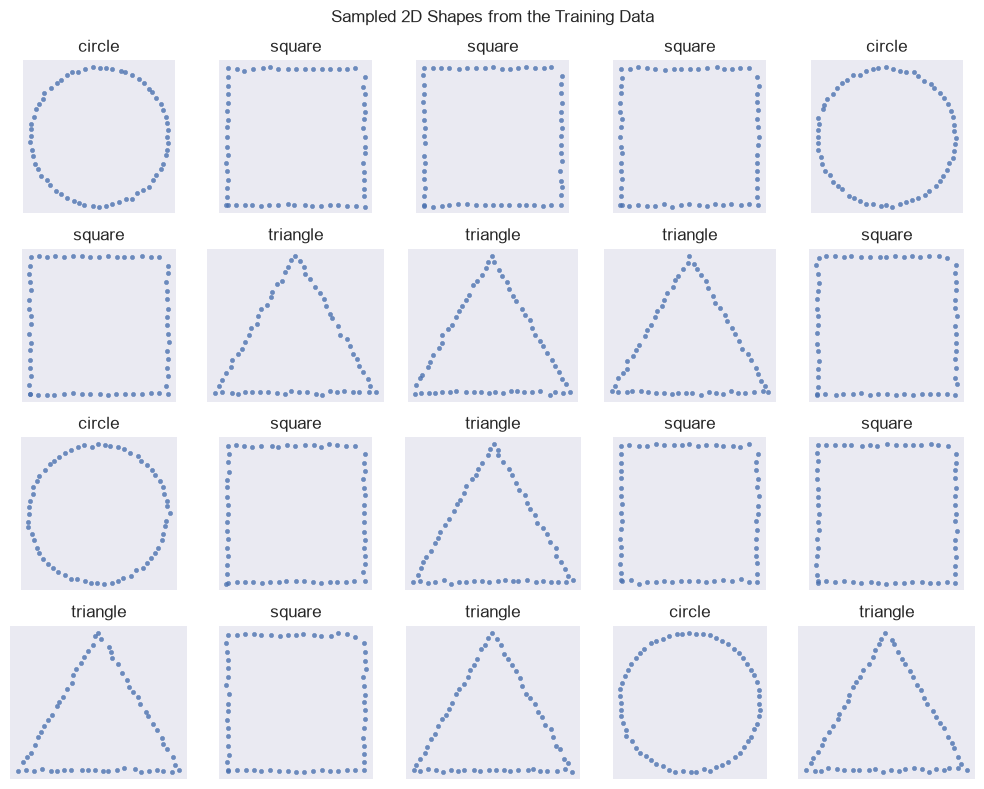

In [86]:
SHAPE_TYPES = ["circle", "square", "triangle"]

def generate_2d_shape(shape_type: str, n_points: int = 64, noise: float = 0.0, randomize: bool = False) -> np.ndarray:
    """Generate a 2D shape as a set of points with EXACT length n_points.

    Ensures fixed-size output so downstream stacking does not fail.
    If a deterministic construction produces fewer points (e.g. triangle edges),
    we upsample by randomly repeating existing points (optionally with tiny jitter).
    """
    if shape_type not in SHAPE_TYPES:
        raise ValueError(f"Unknown shape: {shape_type}")

    if shape_type == "circle":
        angles = np.linspace(0, 2 * np.pi, n_points, endpoint=False) if not randomize else np.random.rand(n_points) * 2 * np.pi
        x = np.cos(angles)
        y = np.sin(angles)
        points = np.stack([x, y], axis=1)

    elif shape_type == "square":
        if not randomize:
            # Distribute points roughly evenly across four edges
            base = n_points // 4
            rem = n_points % 4
            counts = [base + (i < rem) for i in range(4)]  # allocate remainder
            edges_vals = [
                np.linspace(-1, 1, c, endpoint=False) if c > 0 else np.array([]) for c in counts
            ]
            # Right, Left, Top, Bottom (avoid duplicating corners due to endpoint=False)
            points = np.concatenate(
                [
                    np.stack([np.ones(len(edges_vals[0])), edges_vals[0]], axis=1),
                    np.stack([-np.ones(len(edges_vals[1])), edges_vals[1]], axis=1),
                    np.stack([edges_vals[2], np.ones(len(edges_vals[2]))], axis=1),
                    np.stack([edges_vals[3], -np.ones(len(edges_vals[3]))], axis=1),
                ],
                axis=0,
            )
        else:
            choices = np.random.choice(4, size=n_points)
            t = np.random.uniform(-1, 1, size=n_points)
            points = np.zeros((n_points, 2))
            points[choices == 0] = np.stack([np.ones(np.sum(choices == 0)), t[choices == 0]], axis=1)
            points[choices == 1] = np.stack([-np.ones(np.sum(choices == 1)), t[choices == 1]], axis=1)
            points[choices == 2] = np.stack([t[choices == 2], np.ones(np.sum(choices == 2))], axis=1)
            points[choices == 3] = np.stack([t[choices == 3], -np.ones(np.sum(choices == 3))], axis=1)

    else:  # triangle
        vertices = np.array([[0, 1], [-math.sqrt(3) / 2, -0.5], [math.sqrt(3) / 2, -0.5]])
        if not randomize:
            base = n_points // 3
            rem = n_points % 3
            counts = [base + (i < rem) for i in range(3)]
            edges = []
            for i in range(3):
                start = vertices[i]
                end = vertices[(i + 1) % 3]
                c = counts[i]
                if c > 0:
                    edge = np.linspace(start, end, c, endpoint=False)
                    edges.append(edge)
            points = np.concatenate(edges, axis=0)
        else:
            # Uniform sampling along the edges of each length of the triangle
            choices = np.random.choice(3, size=n_points)
            t = np.random.uniform(0, 1, size=n_points)
            points = np.zeros((n_points, 2))
            for i in range(3):
                start = vertices[i]
                end = vertices[(i + 1) % 3]
                mask = choices == i
                points[mask] = np.outer(1 - t[mask], start) + np.outer(t[mask], end)

    # Enforce exact length in case construction mismatch (safety net)
    current = points.shape[0]
    if current < n_points:
        extra_idx = np.random.choice(current, n_points - current, replace=True)
        extra = points[extra_idx] + np.random.normal(scale=noise * 0.1, size=(n_points - current, points.shape[1]))
        points = np.concatenate([points, extra], axis=0)
    elif current > n_points:
        points = points[:n_points]

    if randomize:
        perm = np.random.permutation(points.shape[0])
        points = points[perm]

    points += np.random.normal(scale=noise, size=points.shape)
    return points[:n_points]


def make_fixed_shape_dataset(num_samples: int = 10000, n_points: int = 64, noise: float = 0.01) -> Tuple[torch.Tensor, torch.Tensor]:
    samples = []
    labels = []
    for _ in range(num_samples):
        label = random.randrange(len(SHAPE_TYPES))
        pts = generate_2d_shape(SHAPE_TYPES[label], n_points=n_points, noise=noise, randomize=False)
        samples.append(pts)
        labels.append(label)
    data = torch.tensor(np.stack(samples), dtype=torch.float32)
    targets = torch.tensor(labels, dtype=torch.long)
    return data, targets


class FixedShapeDataset(Dataset):
    def __init__(self, data: torch.Tensor, labels: torch.Tensor):
        self.points = data
        self.labels = labels
        self.inputs = data.reshape(data.size(0), -1)

    def __len__(self) -> int:
        return self.labels.size(0)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        return {
            "points": self.points[idx],
            "inputs": self.inputs[idx],
            "labels": self.labels[idx],
        }


def dict_collate(batch: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
    keys = batch[0].keys()
    collated = {}
    for key in keys:
        collated[key] = torch.stack([item[key] for item in batch], dim=0)
    return collated

fixed_points, fixed_labels = make_fixed_shape_dataset(num_samples=10000, n_points=64, noise=0.01)
fixed_dataset = FixedShapeDataset(fixed_points, fixed_labels)
train_ds, val_ds = random_split(
    fixed_dataset,
    [int(0.8 * len(fixed_dataset)), len(fixed_dataset) - int(0.8 * len(fixed_dataset))],
)

batch_size = 256
train_loader_fixed = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=dict_collate)
val_loader_fixed = DataLoader(val_ds, batch_size=batch_size, shuffle=False, collate_fn=dict_collate)

fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for ax, idx in zip(axes.ravel(), np.random.choice(len(fixed_dataset), size=20, replace=False)):
    sample = fixed_dataset[idx]
    scatter_2d_points(sample["points"].numpy(), SHAPE_TYPES[sample["labels"].item()], ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Sampled 2D Shapes from the Training Data")
plt.tight_layout()

As we can see, the dataset consists of points sampled from three different shapes: circles, squares, and triangles. Each shape is represented by a set of 2D points of a fixed length, and our goal is to classify the shape based on these points. For this, let's build a simple MLP classifier that takes the flattened set of points as input and outputs the predicted shape class:

In [87]:
#| code-fold: false
class ShapeMLP(nn.Module):
    def __init__(self, input_dim: int, hidden_dims: Tuple[int, ...] = (256, 128, 64), num_classes: int = 3, dropout: float = 0.1):
        super().__init__()
        layers: List[nn.Module] = []
        dims = [input_dim, *hidden_dims]
        for in_dim, out_dim in zip(dims[:-1], dims[1:]):
            layers.append(nn.Linear(in_dim, out_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
        self.feature_extractor = nn.Sequential(*layers)
        self.classifier = nn.Linear(hidden_dims[-1], num_classes)

    def forward(self, x: torch.Tensor, return_features: bool = False):
        features = self.feature_extractor(x)
        logits = self.classifier(features)
        if return_features:
            return logits, features
        return logits

# Now train the MLP on the fixed-size shape dataset
mlp_fixed = ShapeMLP(input_dim=64 * 2, hidden_dims=(256, 128, 64), num_classes=len(SHAPE_TYPES))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(mlp_fixed.parameters(), lr=1e-3, weight_decay=1e-4)

def mlp_forward(model, batch, device):
    return model(batch["inputs"].to(device))

history_fixed = train_classifier(
    mlp_fixed,
    train_loader_fixed,
    optimizer,
    criterion,
    epochs=3,
    forward_fn=mlp_forward,
    val_loader=val_loader_fixed,
)

Epoch 01/3 | train_loss=0.3237 train_acc=0.965 | val_loss=0.0000 val_acc=1.000
Epoch 02/3 | train_loss=0.0000 train_acc=1.000 | val_loss=0.0000 val_acc=1.000
Epoch 03/3 | train_loss=0.0000 train_acc=1.000 | val_loss=0.0000 val_acc=1.000


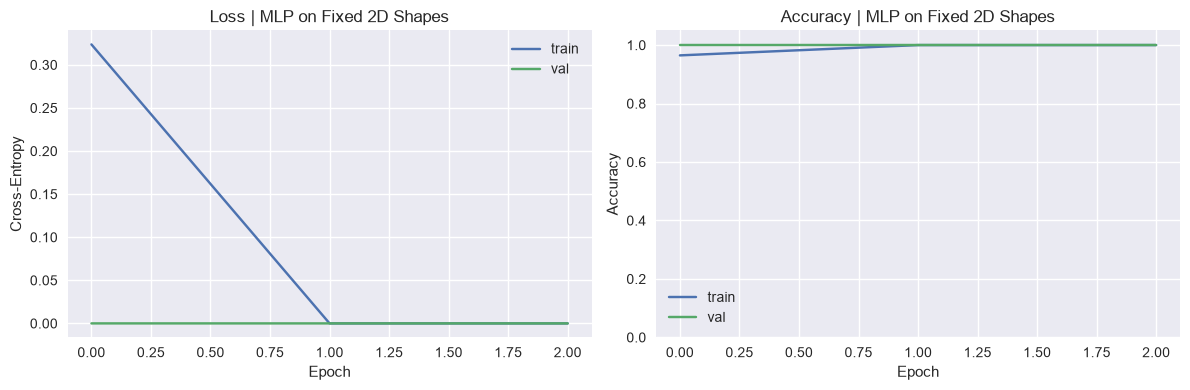

In [88]:
plot_history(history_fixed, "MLP on Fixed 2D Shapes")

Validation accuracy: 100.00%


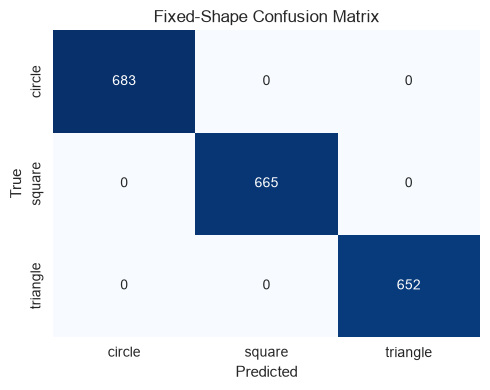

In [89]:
eval_fixed = evaluate_classifier(mlp_fixed, val_loader_fixed, criterion, forward_fn=mlp_forward)
cm_fixed = confusion_matrix(eval_fixed["labels"], eval_fixed["preds"])
plot_confusion(cm_fixed, SHAPE_TYPES, "Fixed-Shape Confusion Matrix")
print(f"Validation accuracy: {eval_fixed['acc'] * 100:.2f}%")

As we can see from the results above, the MLP does a great job on this particular task, achieving high accuracy on the test set. However, one reason for this is that every shape (1) had the same number of points and (2) the points were always presented in the same order. What happens to the MLP if we change these assumptions? Let's explore this next by permuting the order of the points in each set.

## 2D Shapes: Variable-Length Sets with Noise and Shuffling
In reality, we cannot always guarantee that our input sets will have a fixed size or that the points will be presented in a consistent order. For example, if the points we receive come from a 3D scanner or automated unstructured meshing algorithm. To simulate this on our toy example, we will modify our dataset by randomizing the number of points sampled from each shape, including the order, and adding some jitter to the point locations to simulate measurement noise. Let's see how the MLP does in this case. We keep the same MLP architecture but because we do not know the number of points in advance, we are now forced to pad every set to the maximum possible length so the linear layers see a fixed-size vector.

In [90]:
class VariableShapeDataset(Dataset):
    def __init__(self, num_samples: int = 4000, length_range: Tuple[int, int] = (20, 200), noise_std: float = 0.05):
        self.samples: List[torch.Tensor] = []
        self.labels: List[int] = []
        self.length_range = length_range
        self.max_points = length_range[1]
        for _ in range(num_samples):
            label = random.randrange(len(SHAPE_TYPES))
            n_points = random.randint(length_range[0], length_range[1])
            pts = generate_2d_shape(SHAPE_TYPES[label], n_points=n_points, noise=noise_std, randomize=True)
            self.samples.append(torch.tensor(pts, dtype=torch.float32))
            self.labels.append(label)

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        points = self.samples[idx]
        return {
            "points": points,
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
            "length": torch.tensor(points.size(0), dtype=torch.long),
        }


def build_variable_collate(max_points: int, feature_dim: int = 2):
    def collate(batch: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
        batch_size = len(batch)
        padded = torch.zeros(batch_size, max_points, feature_dim)
        mask = torch.ones(batch_size, max_points, dtype=torch.bool)
        labels = torch.zeros(batch_size, dtype=torch.long)
        for i, item in enumerate(batch):
            n = min(item["points"].size(0), max_points)
            padded[i, :n] = item["points"][:n]
            mask[i, :n] = False
            labels[i] = item["labels"]
        flat = padded.reshape(batch_size, -1)
        return {"points": padded, "mask": mask, "inputs": flat, "labels": labels}

    return collate

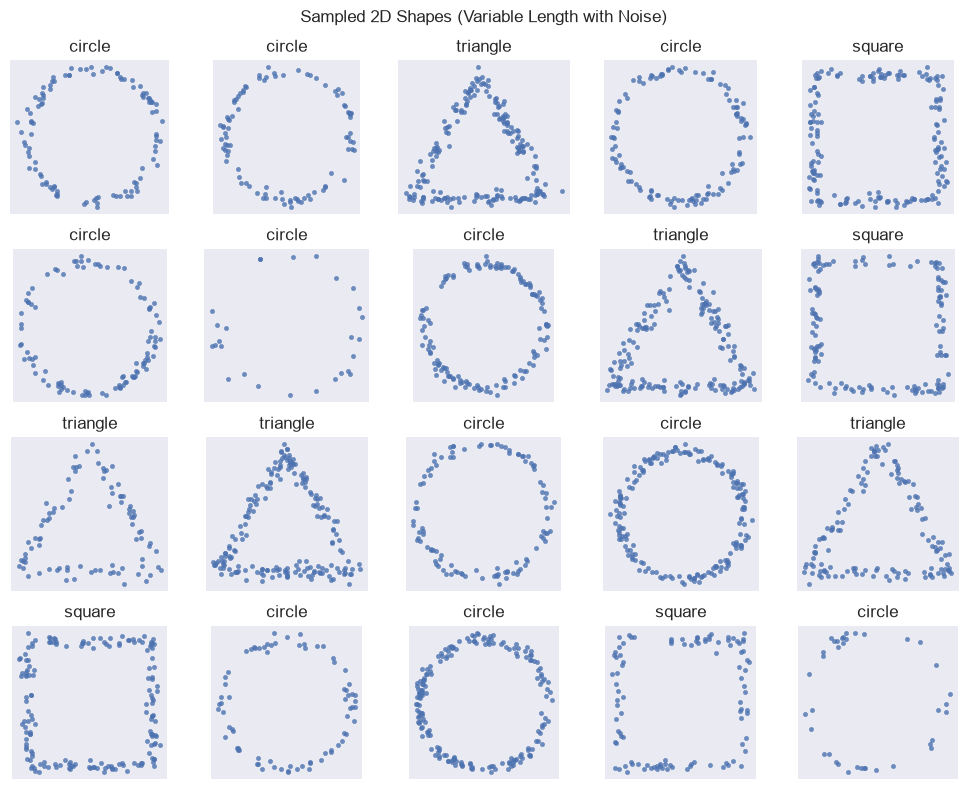

In [91]:
# Visualize some variable-length shapes
var_dataset = VariableShapeDataset(num_samples=20, length_range=(20, 200), noise_std=0.05)
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for ax, idx in zip(axes.ravel(), range(len(var_dataset))):
    sample = var_dataset[idx]
    scatter_2d_points(sample["points"].numpy(), SHAPE_TYPES[sample["labels"].item()], ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Sampled 2D Shapes (Variable Length with Noise)")
plt.tight_layout()
plt.show()

Epoch 01/10 | train_loss=1.0798 train_acc=0.333 | val_loss=1.0585 val_acc=0.373
Epoch 02/10 | train_loss=1.0026 train_acc=0.459 | val_loss=1.0358 val_acc=0.470
Epoch 03/10 | train_loss=0.8053 train_acc=0.652 | val_loss=0.9977 val_acc=0.503
Epoch 04/10 | train_loss=0.4709 train_acc=0.822 | val_loss=1.0405 val_acc=0.533
Epoch 05/10 | train_loss=0.2412 train_acc=0.912 | val_loss=1.2622 val_acc=0.556
Epoch 06/10 | train_loss=0.1446 train_acc=0.949 | val_loss=1.4795 val_acc=0.563
Epoch 07/10 | train_loss=0.1050 train_acc=0.967 | val_loss=1.6993 val_acc=0.561
Epoch 08/10 | train_loss=0.0786 train_acc=0.975 | val_loss=1.9264 val_acc=0.553
Epoch 09/10 | train_loss=0.0707 train_acc=0.977 | val_loss=2.1034 val_acc=0.540
Epoch 10/10 | train_loss=0.0817 train_acc=0.974 | val_loss=2.1032 val_acc=0.550
Noise 0.01 | MLP accuracy: 55.0%
Epoch 01/10 | train_loss=1.0736 train_acc=0.360 | val_loss=1.0497 val_acc=0.400
Epoch 02/10 | train_loss=0.9543 train_acc=0.528 | val_loss=1.0328 val_acc=0.443
Epoch 0

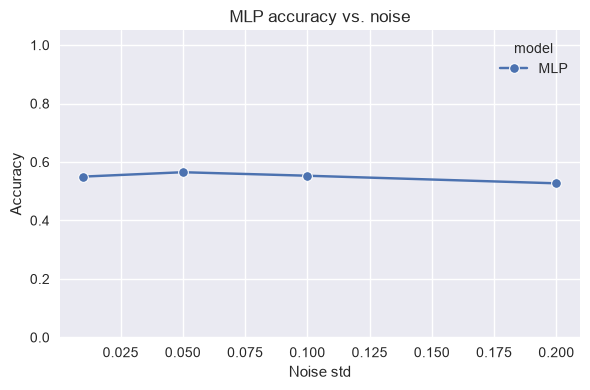

In [92]:
#| code-fold: false
noise_levels = [0.01, 0.05, 0.1, 0.2]
mlp_variable_results = []

for noise in noise_levels:
    dataset = VariableShapeDataset(num_samples=5000, length_range=(20, 200), noise_std=noise)
    collate_fn = build_variable_collate(dataset.max_points, feature_dim=2)
    train_ds, val_ds = random_split(
        dataset,
        [int(0.8 * len(dataset)), len(dataset) - int(0.8 * len(dataset))],
    )
    train_loader = DataLoader(train_ds, batch_size=192, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, collate_fn=collate_fn)

    mlp = ShapeMLP(input_dim=dataset.max_points * 2, hidden_dims=(512, 256, 128), num_classes=len(SHAPE_TYPES))
    optimizer = torch.optim.AdamW(mlp.parameters(), lr=1e-3, weight_decay=5e-4)
    history = train_classifier(
        mlp,
        train_loader,
        optimizer,
        criterion,
        epochs=10,
        forward_fn=mlp_forward,
        val_loader=val_loader,
    )
    metrics = evaluate_classifier(mlp, val_loader, criterion, forward_fn=mlp_forward)
    mlp_variable_results.append({"model": "MLP", "noise": noise, "accuracy": metrics["acc"]})
    print(f"Noise {noise:.2f} | MLP accuracy: {metrics['acc'] * 100:.1f}%")

mlp_variable_df = pd.DataFrame(mlp_variable_results)
plot_metric_curve(mlp_variable_df, "MLP accuracy vs. noise")

We see now that unlike before, the MLP's performance degrades significantly as we introduce variability in the input sets. This is because the MLP relies on a consistent ordering and number of points to learn meaningful patterns, and when these assumptions are violated, it struggles to generalize. We can fix this by instead operating on *sets* of unordered points rather than flattened vectors where we assume that everything is consistently ordered. To enable this, we will use a transformer architecture that can handle variable-length sets and is invariant to the order of the points.

## What Is a Transformer?

At a high level, a transformer is a **function on sets or sequences of vectors** that learns _how much each element should pay attention to every other element_ when computing a new representation.



Given an input set (or sequence)

$$X = [x_1, x_2, \dots, x_n], \qquad x_i \in \mathbb{R}^d,$$

a single **self-attention layer** produces new vectors $z_i$:

$$Z = [z_1, z_2, \dots, z_n], \qquad z_i \in \mathbb{R}^{d_{\text{model}}}.$$



It involves three key steps:

1. **Linear projections** (learned):

   $$q_i = W_Q x_i, \quad k_i = W_K x_i, \quad v_i = W_V x_i,$$

   where $W_Q, W_K, W_V$ are matrices.

2. **Attention weights** from pairwise similarity of queries and keys:

   $$a_{ij} = \text{softmax}_j\left(\frac{q_i^\top k_j}{\sqrt{d_k}}\right),$$

   which say how much point $i$ listens to point $j$. The division by $\sqrt{d_k}$ is a scaling factor that helps with training stability since the dot products can grow large in magnitude as the dimension $d_k$ increases, and thus push the softmax into regions with very small gradients (see Exercises below), so the square root helps normalize the variance of the dot products. The softmax ensures the weights sum to 1 across $j$ for each fixed $i$.[^tr-18-1]

3. **Weighted aggregation of values**:

   $$z_i = \sum_{j=1}^n a_{ij} v_j.$$

   which produces the new representation for point $i$.


Typically, multiple attention heads are run in parallel (with different $W_Q, W_K, W_V$) and their outputs are concatenated and mixed with a small MLP. Stacking these layers produces a network that can attend globally to the whole set with content-dependent weights, unlike convolutions which can only attend across a short window.

For transformers in general, there is a rich set of possible variants and add-ons that one can include or study, but for this chapter we will keep it simple and try to build intuition using only unordered point sets. This means we will not be doing certain common operations in transformers like adding positional encoders or similar.

[^tr-18-1]: The softmax function is defined as follows: for a vector $z \in \mathbb{R}^n$, the softmax of $z$ is a vector $\text{softmax}(z) \in \mathbb{R}^n$ where each component is given by $$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_{j=1}^n e^{z_j}}.$$

### MLPs vs. Transformers on Sets



Let's compare **how** the two architectures operate on the same data.



**MLP view of a point set**



For the variable-length experiment, we padded each set to a common maximum size $N_\text{max}$ and then _flatten_ all coordinates into a single long vector:

$$x = [p_{1,x}, p_{1,y}, \dots, p_{N_\text{max},x}, p_{N_\text{max},y}]^\top \in \mathbb{R}^{2N_\text{max}}.$$

An $L$-layer MLP implements a composition of affine maps and pointwise nonlinearities

$$f_\text{MLP}(x) = W_L \sigma( W_{L-1} \sigma( \cdots \sigma(W_1 x + b_1) ) + b_{L-1}) + b_L.$$



**Key properties of this representation:**

- Each coordinate position (e.g., "entry 17") has a **fixed semantic meaning** during training.

- If we change the **ordering or count** of points, the mapping from "position index" to "physical location in the shape" is destroyed.

- As a result, the MLP **is not permutation-invariant**: shuffling points changes the prediction in an uncontrolled way.



**Transformer view of the same set**



The transformer instead keeps the set as a matrix

$$X \in \mathbb{R}^{N_\text{max} \times d}, \quad d=2 \text{ for 2D; } X_i = p_i,$$

and produces a new matrix $Z \in \mathbb{R}^{N_\text{max} \times d_\text{model}}$ by self-attention. Classification then uses either

- a special **CLS token** $z_\text{CLS}$: an extra learned point whose output we use as the summary of the set, or

- a permutation-invariant pooling (mean or max) over rows of $Z$.



If we mask out padded rows and ignore them in attention, then:

- Reordering the **actual points** corresponds to permuting the rows of $X$.

- Self-attention does not care about this order: if we shuffle the points, it returns the same new vectors $z_i$, shuffled in the same way. Each $z_i$ is a sum over all points $j$, and a sum does not depend on the order of its terms.

- Self-attention plus pooling can be made **permutation-invariant** over the true points.


This means that the output of the transformer depends only on the **set** of points, not on their ordering, which is what we need if we cannot rely on a fixed ordering or input sequence. The experiment below shows this numerically: once we break the ordering assumption the transformer will still be able to perform well, where the MLP degraded above.

### Transformer Encoder for Sets
We now treat each point as a token, project $(x, y)$ into a latent space, and apply stacked self-attention blocks with a learned CLS token for global pooling. Before we jump into the full transformer encoder, let's first build and train a **tiny single-head self-attention model** on top of simple 2D shapes. The goal is not to get state-of-the-art accuracy, but to have a model with **one attention head and only 3 latent dimensions** ($d_\text{model} = 3$) so that we can plot:

- the **linear projections** $W_Q, W_K, W_V$ applied to each point,
- the resulting **attention weights** $a_{ij}$ across the set,
- the **aggregated features** $z_i = \sum_j a_{ij} v_j$.

We will first train a very small transformer on a toy classification task (only a few 2D shapes), and then visualize what it has learned.

The code below defines `SelfAttentionBlock`, the block our models train with. It adds a *residual connection*: it returns $h_i = x_i + z_i$ instead of just $z_i$. In this way, each point keeps its own features and adds what it gathered from the other points. Without it, each layer replaces every point by a weighted average of the points, and a few such layers in a row pull all the points toward each other. After the attention step, the block applies a small MLP to each point, again with a residual connection: $h_i \leftarrow h_i + \text{MLP}(h_i)$.

The block also takes a `key_padding_mask`. Attention itself works for any number of points, but to train on many sets at once, PyTorch needs one tensor for the whole batch, so all sets in it must have the same length. We fill the shorter sets up with dummy points at $(0, 0)$, which is called padding. The mask marks the dummy points. Their scores are set to $-\infty$, so they get weight 0 after the softmax, and the pooling at the end of the model skips them too. So padding changes nothing for the real points. It only lets us process many sets of different sizes together.

In [93]:
#| code-fold: false
class SelfAttentionBlock(nn.Module):
    """Batched single-head self-attention block with residual connections and a small feedforward.

    This block provides the interface expected by ToySetTransformer:
    - forward(x, key_padding_mask=None) -> (h, attn)
      where x: (B, N, d_model), h: (B, N, d_model), attn: (B, N, N)
    """

    def __init__(self, d_model: int = 3, dim_feedforward: int = 16, dropout: float = 0.0):
        super().__init__()
        self.d_model = d_model
        # Projections operate on d_model inputs (assumes input already projected to d_model)
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)

        # small position-wise feedforward for demonstration
        self.ff = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.ReLU(),
            nn.Linear(dim_feedforward, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor, key_padding_mask: Optional[torch.Tensor] = None):
        """Forward pass for batched inputs.

        Parameters
        ----------
        x : (B, N, d_model)
        key_padding_mask : (B, N) boolean mask where True indicates padding positions to ignore
        """
        # Projections
        Q = self.W_q(x)  # (B, N, d)
        K = self.W_k(x)  # (B, N, d)
        V = self.W_v(x)  # (B, N, d)

        # Scaled dot-product attention logits and weights
        scale = math.sqrt(self.d_model)
        logits = torch.matmul(Q, K.transpose(-2, -1)) / scale  # (B, N, N)

        if key_padding_mask is not None:
            # key_padding_mask: True for padded tokens -> we want to set logits to -inf
            # Expand to (B, N, N) to mask keys for each query
            mask = key_padding_mask.unsqueeze(1).expand(-1, logits.size(1), -1)  # (B, N, N)
            logits = logits.masked_fill(mask, float("-inf"))

        A = torch.softmax(logits, dim=-1)  # (B, N, N)

        # Aggregate values
        Z = torch.matmul(A, V)  # (B, N, d)

        # Residual connection: each point keeps its own features x
        # and adds what it gathered from the other points (Z)
        h = x + Z  # (B, N, d)

        # Small feedforward on each point, again with a residual connection
        h = h + self.ff(h)  # (B, N, d)

        return h, A

class ToySetTransformer(nn.Module):
    """Tiny transformer on 2D point sets for interpretability.

    - Single head
    - d_model = 3 (so every matrix fits on the page)
    - One encoder block
    - Mean pooling over points for classification
    """

    def __init__(self, num_classes: int = 3, d_model: int = 3):
        super().__init__()
        self.input_proj = nn.Linear(2, d_model)
        self.attn_block = SelfAttentionBlock(d_model=d_model, dim_feedforward=16, dropout=0.0)
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, num_classes),
        )

    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None, return_internals: bool = False):
        # x: (B, N, 2)
        h = self.input_proj(x)
        h, attn = self.attn_block(h, key_padding_mask=mask)

        if mask is not None:
            valid = (~mask).unsqueeze(-1)  # (B, N, 1)
            summed = (h * valid).sum(dim=1)
            counts = valid.sum(dim=1).clamp_min(1.0)
            pooled = summed / counts
        else:
            pooled = h.mean(dim=1)

        logits = self.classifier(pooled)

        if return_internals:
            return logits, {"h": h, "attn": attn}
        return logits

In [94]:
# 2D toy dataset for the tiny transformer: triangle vs square vs circle
def make_toy_transformer_dataset(num_samples: int = 1200, n_points_range: Tuple[int, int] = (16, 24), noise: float = 0.03):
    samples = []
    labels = []
    for _ in range(num_samples):
        label = random.randrange(len(SHAPE_TYPES))
        n_points = random.randint(*n_points_range)
        pts = generate_2d_shape(SHAPE_TYPES[label], n_points=n_points, noise=noise, randomize=True)
        samples.append(torch.tensor(pts, dtype=torch.float32))
        labels.append(label)

    return samples, torch.tensor(labels, dtype=torch.long)


class ToyTransformerDataset(Dataset):
    def __init__(self, samples: List[torch.Tensor], labels: torch.Tensor, max_points: int = 24):
        self.samples = samples
        self.labels = labels
        self.max_points = max_points

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        pts = self.samples[idx]
        n = min(pts.size(0), self.max_points)
        padded = torch.zeros(self.max_points, 2)
        mask = torch.ones(self.max_points, dtype=torch.bool)
        padded[:n] = pts[:n]
        mask[:n] = False
        return {"points": padded, "mask": mask, "labels": self.labels[idx]}


def toy_collate(batch: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
    points = torch.stack([b["points"] for b in batch], dim=0)
    mask = torch.stack([b["mask"] for b in batch], dim=0)
    labels = torch.stack([b["labels"] for b in batch], dim=0)
    return {"points": points, "mask": mask, "labels": labels}


# Build toy dataset and dataloaders
toy_samples, toy_labels = make_toy_transformer_dataset(num_samples=1500, n_points_range=(16, 24), noise=0.0001)
toy_max_points = 24
toy_dataset = ToyTransformerDataset(toy_samples, toy_labels, max_points=toy_max_points)
toy_train_size = int(0.8 * len(toy_dataset))
toy_val_size = len(toy_dataset) - toy_train_size
toy_train_ds, toy_val_ds = random_split(toy_dataset, [toy_train_size, toy_val_size])

toy_batch_size = 512
toy_train_loader = DataLoader(toy_train_ds, batch_size=toy_batch_size, shuffle=True, collate_fn=toy_collate)
toy_val_loader = DataLoader(toy_val_ds, batch_size=toy_batch_size, shuffle=True, collate_fn=toy_collate)

In [95]:
#| code-fold: false
toy_model = ToySetTransformer(num_classes=len(SHAPE_TYPES), d_model=3)
toy_optimizer = torch.optim.AdamW(toy_model.parameters(), lr=5e-3, weight_decay=1e-4)

def toy_forward(model, batch, device):
    return model(batch["points"].to(device), mask=batch["mask"].to(device))

toy_history = train_classifier(
    toy_model,
    toy_train_loader,
    toy_optimizer,
    criterion,
    epochs=150,
    forward_fn=toy_forward,
    val_loader=toy_val_loader,
)

Epoch 01/150 | train_loss=1.3525 train_acc=0.338 | val_loss=1.2591 val_acc=0.347
Epoch 02/150 | train_loss=1.2564 train_acc=0.338 | val_loss=1.1774 val_acc=0.347
Epoch 03/150 | train_loss=1.1637 train_acc=0.339 | val_loss=1.1283 val_acc=0.350
Epoch 04/150 | train_loss=1.1116 train_acc=0.361 | val_loss=1.1143 val_acc=0.323
Epoch 05/150 | train_loss=1.0973 train_acc=0.366 | val_loss=1.1212 val_acc=0.290
Epoch 06/150 | train_loss=1.1013 train_acc=0.343 | val_loss=1.1256 val_acc=0.287
Epoch 07/150 | train_loss=1.1032 train_acc=0.319 | val_loss=1.1208 val_acc=0.287
Epoch 08/150 | train_loss=1.0994 train_acc=0.326 | val_loss=1.1124 val_acc=0.287
Epoch 09/150 | train_loss=1.0952 train_acc=0.333 | val_loss=1.1064 val_acc=0.280
Epoch 10/150 | train_loss=1.0927 train_acc=0.332 | val_loss=1.1034 val_acc=0.273
Epoch 11/150 | train_loss=1.0921 train_acc=0.339 | val_loss=1.1019 val_acc=0.293
Epoch 12/150 | train_loss=1.0924 train_acc=0.333 | val_loss=1.1010 val_acc=0.307
Epoch 13/150 | train_loss=1.

Toy transformer validation accuracy: 98.0%


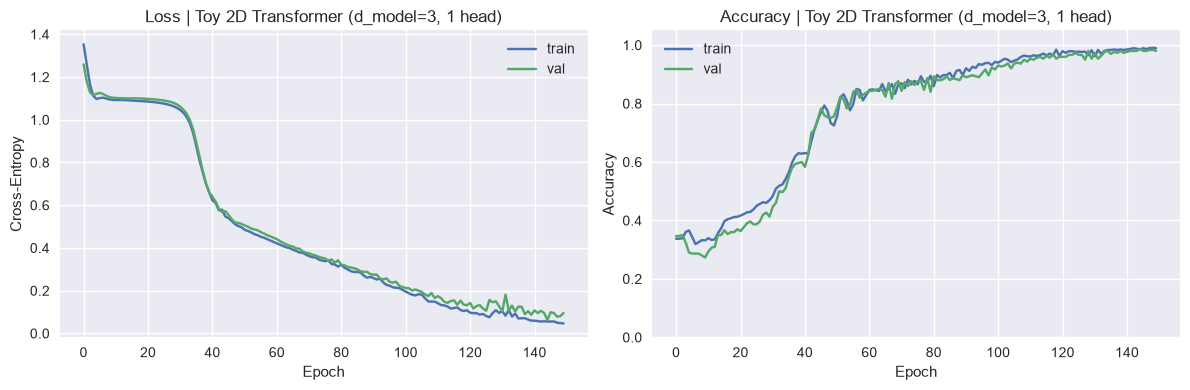

In [96]:
plot_history(toy_history, "Toy 2D Transformer (d_model=3, 1 head)")

toy_val_metrics = evaluate_classifier(toy_model, toy_val_loader, criterion, forward_fn=toy_forward)
print(f"Toy transformer validation accuracy: {toy_val_metrics['acc'] * 100:.1f}%")

In [97]:
# Pick one validation set of the toy model to look at in the figures below
toy_batch = next(iter(toy_val_loader))
toy_points, toy_mask = toy_batch["points"][0], toy_batch["mask"][0]
toy_pts_np = toy_points[~toy_mask].numpy()  # keep only the real (unpadded) points
toy_label = SHAPE_TYPES[toy_batch["labels"][0].item()]

### The attention step, number by number

The figure below shows every number of one attention step of the toy model, on 8 points of one shape from the toy model's validation set. The model has $d_\text{model} = 3$.

- The input projection and $W_Q$, $W_K$, $W_V$ turn each point into a query, a key and a value: one row of $Q$, $K$ and $V$, with 3 numbers each.
- The score matrix $S = Q K^\top / \sqrt{d_k}$ holds one number for each pair of points. Entry $(i, j)$ is the dot product of the query of point $i$ with the key of point $j$, divided by $\sqrt{d_k}$.
- The softmax turns each row of $S$ into a row of the attention matrix $A$, with positive weights that add up to 1. Larger scores get larger weights.
- Row $i$ of $Z = A V$ is what point $i$ receives: the values of all points, averaged with the weights in row $i$ of $A$.

The red frames follow one query, point 0, through these steps. The dashed frames mark what one other point, point 3, offers to the other points: its key, its value, and its column in $S$ and $A$. The colors repeat the numbers: red is high and blue is low, and in $A$ yellow is high.

In a running notebook, the sliders move a point, pick the query and multiply all scores by a factor. Move point 3. Which numbers change in $Q$, $K$ and $V$, and which change in $S$, $A$ and $Z$? Why does moving one point change what every point receives? Then multiply the scores by 0.05 and by 20. What happens to the rows of $A$, and to the rows of $Z$?

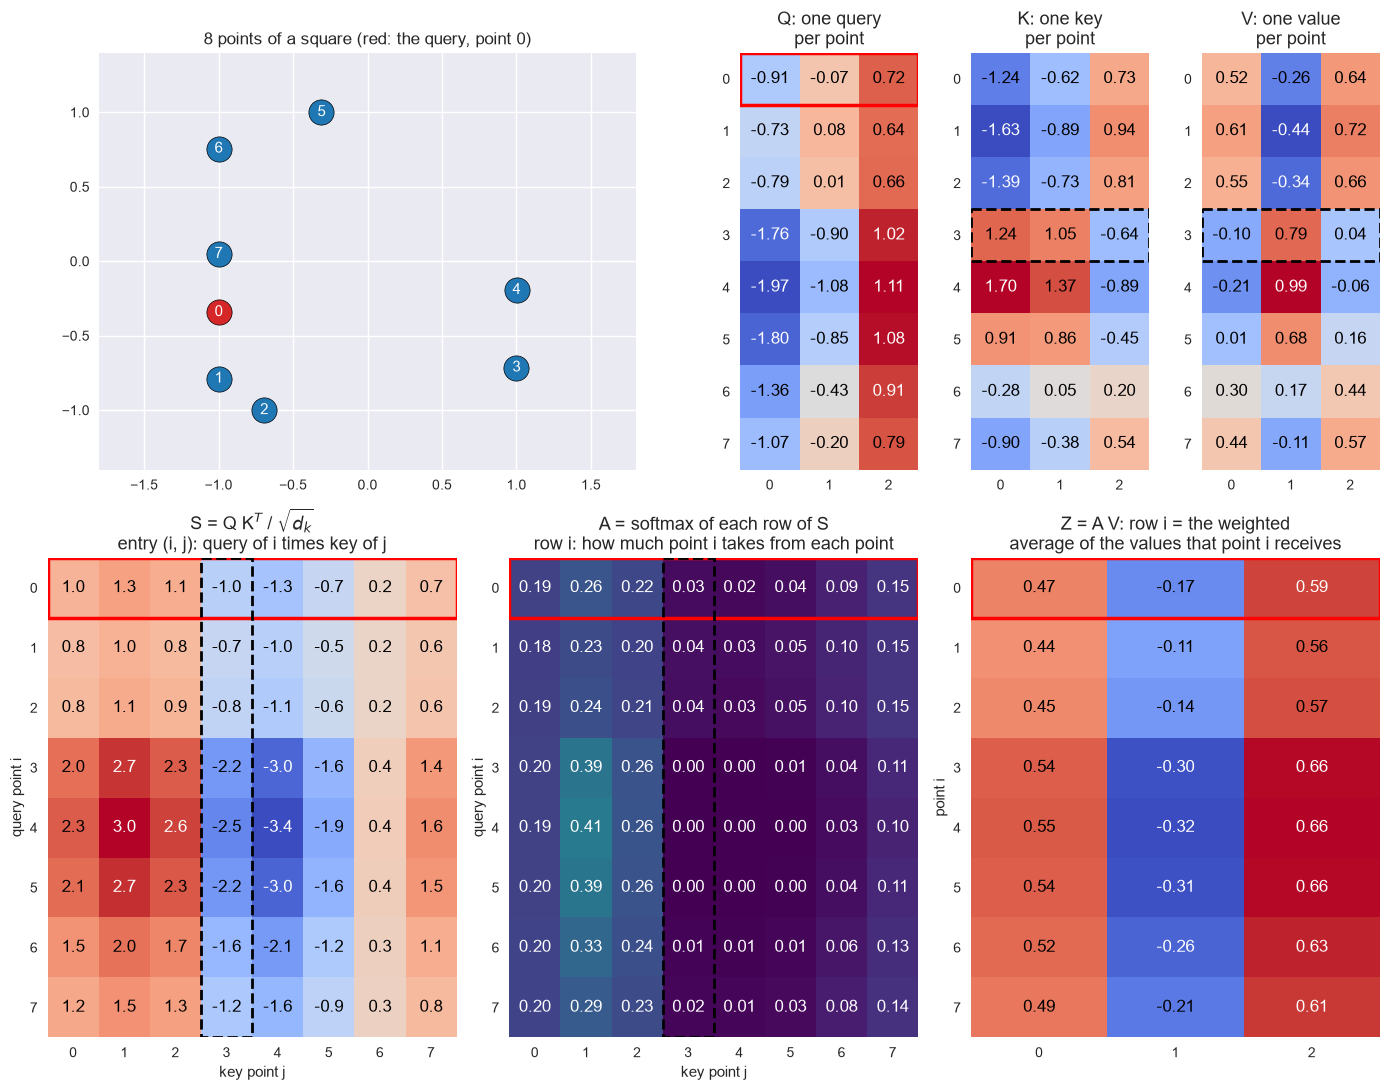

In [98]:
# The attention step, number by number: 8 points of the toy set, passed through the trained toy model's attention block.
# Sliders move one point, pick the query and scale the scores; they need a running notebook, the book shows the start.
import ipywidgets as widgets
from IPython.display import display

eight_order = np.argsort(np.arctan2(toy_pts_np[:, 1] - toy_pts_np[:, 1].mean(), toy_pts_np[:, 0] - toy_pts_np[:, 0].mean()))
eight_points = toy_pts_np[eight_order[np.linspace(0, len(eight_order) - 1, 8).round().astype(int)]].copy()
n_eight = len(eight_points)


def attention_numbers(points, factor):
    """Q, K, V, the scores S, the weights A and the outputs Z = A V of the toy model's attention block."""
    block = toy_model.attn_block
    with torch.no_grad():
        x = toy_model.input_proj(torch.tensor(points, dtype=torch.float32).to(DEVICE))
        Q8, K8, V8 = block.W_q(x), block.W_k(x), block.W_v(x)
        S8 = factor * (Q8 @ K8.T) / math.sqrt(block.d_model)
        A8 = torch.softmax(S8, dim=-1)
        Z8 = A8 @ V8
    return [M.cpu().numpy() for M in (Q8, K8, V8, S8, A8, Z8)]


def number_table(ax, M, title, cmap, row=None, col=None, row2=None, vmin=None, vmax=None, decimals=2):
    """Draw a matrix as a table of numbers on colored cells; frame one row (red), one column or one more row (dashed)."""
    image = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            r, g_, b, _ = image.cmap(image.norm(M[i, j]))  # dark cell -> white text
            color = "white" if 0.299 * r + 0.587 * g_ + 0.114 * b < 0.45 else "black"
            ax.text(j, i, f"{M[i, j]:.{decimals}f}", ha="center", va="center", fontsize=12, color=color)
    if row is not None:
        ax.add_patch(plt.Rectangle((-0.5, row - 0.5), M.shape[1], 1, fill=False, ec="red", lw=2.5))
    if row2 is not None:
        ax.add_patch(plt.Rectangle((-0.5, row2 - 0.5), M.shape[1], 1, fill=False, ec="black", lw=2, ls="--"))
    if col is not None:
        ax.add_patch(plt.Rectangle((col - 0.5, -0.5), 1, M.shape[0], fill=False, ec="black", lw=2, ls="--"))
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))
    ax.grid(False)
    ax.set_title(title, fontsize=13)


def draw_step(moved_point, dx, dy, query, factor):
    points = eight_points.copy()
    points[moved_point] += [dx, dy]
    Q8, K8, V8, S8, A8, Z8 = attention_numbers(points, factor)

    fig = plt.figure(figsize=(14, 11))
    grid = fig.add_gridspec(2, 6, height_ratios=[1, 1.15])
    ax = fig.add_subplot(grid[0, 0:3])
    if dx != 0 or dy != 0:
        ax.scatter(*eight_points[moved_point], s=150, facecolors="none", edgecolors="gray", ls="--")
    for i, (px, py) in enumerate(points):
        ax.scatter(px, py, s=330, c="tab:red" if i == query else "tab:blue", edgecolors="k", linewidths=0.5, zorder=3)
        ax.text(px, py, str(i), ha="center", va="center", color="white", fontsize=11, zorder=4)
    ax.set_aspect("equal")
    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-1.4, 1.4)
    ax.set_title(f"8 points of a {toy_label} (red: the query, point {query})")
    number_table(fig.add_subplot(grid[0, 3]), Q8, "Q: one query\nper point", "coolwarm", row=query)
    number_table(fig.add_subplot(grid[0, 4]), K8, "K: one key\nper point", "coolwarm", row2=moved_point)
    number_table(fig.add_subplot(grid[0, 5]), V8, "V: one value\nper point", "coolwarm", row2=moved_point)
    ax = fig.add_subplot(grid[1, 0:2])
    number_table(ax, S8, "S = Q K$^T$ / $\\sqrt{d_k}$\nentry (i, j): query of i times key of j", "coolwarm",
                 row=query, col=moved_point, decimals=1)
    ax.set_xlabel("key point j")
    ax.set_ylabel("query point i")
    ax = fig.add_subplot(grid[1, 2:4])
    number_table(ax, A8, "A = softmax of each row of S\nrow i: how much point i takes from each point", "viridis",
                 row=query, col=moved_point, vmin=0, vmax=1, decimals=2)
    ax.set_xlabel("key point j")
    ax.set_ylabel("query point i")
    ax = fig.add_subplot(grid[1, 4:6])
    number_table(ax, Z8, "Z = A V: row i = the weighted\naverage of the values that point i receives", "coolwarm",
                 row=query)
    ax.set_ylabel("point i")
    plt.tight_layout()
    plt.close(fig)
    return fig


step_controls = dict(
    moved_point=widgets.IntSlider(value=3, min=0, max=n_eight - 1, description="moved point", continuous_update=False),
    dx=widgets.FloatSlider(value=0.0, min=-0.5, max=0.5, step=0.1, description="shift in x", continuous_update=False),
    dy=widgets.FloatSlider(value=0.0, min=-0.5, max=0.5, step=0.1, description="shift in y", continuous_update=False),
    query=widgets.IntSlider(value=0, min=0, max=n_eight - 1, description="query", continuous_update=False),
    factor=widgets.FloatLogSlider(value=1.0, base=10, min=-2, max=2, step=0.1, description="score factor",
                                  continuous_update=False),
)
display(widgets.HBox(list(step_controls.values()), layout=widgets.Layout(flex_flow="row wrap")))
step_handle = display(draw_step(**{k: c.value for k, c in step_controls.items()}), display_id=True)
for c in step_controls.values():
    c.observe(lambda change: step_handle.update(draw_step(**{k: s.value for k, s in step_controls.items()})), names="value")

### Explore the attention of the toy model

The two figures below let you change the toy model's attention and watch what happens. Both use the trained toy model. The first figure works in this book and in a notebook. The second one needs a running notebook (VS Code or Colab); in the book, it shows only its starting state.

**How sharp is the attention?** To demonstrate the effect of the softmax, the slider multiplies all the scores $q_i^\top k_j / \sqrt{d_k}$ by a factor $c$, from 0.01 to 100. The trained model has $c = 1$. The left panel colors the set by the weights of the circled query point. The right panel shows the same weights sorted from largest to smallest, and the dashed line marks equal weights $1/N$. How does the query listen to the other points when $c$ is small, and when it is large? For which values of $c$ does every point receive the same thing from the other points, and why?

In [99]:
# Interactive: multiply the scores of the toy model by a factor c and watch the weights concentrate.
# Every slider position is computed in advance, so the slider also works in the HTML version of this book.
import plotly.graph_objects as go
from plotly.subplots import make_subplots

block = toy_model.attn_block
with torch.no_grad():
    toy_embed = toy_model.input_proj(torch.tensor(toy_pts_np).to(DEVICE))
    base_scores = (block.W_q(toy_embed) @ block.W_k(toy_embed).T / math.sqrt(block.d_model)).cpu().numpy()
n_toy = len(toy_pts_np)
query = 0
factors = np.logspace(-2, 2, 33)  # from 0.01 to 100; index 16 is the trained model (c = 1)


def weights_at(c):
    """Weights of all queries for the scores multiplied by c."""
    s = c * base_scores
    w = np.exp(s - s.max(axis=1, keepdims=True))
    return w / w.sum(axis=1, keepdims=True)


def title_at(c, w):
    entropy = -(w[query] * np.log(w[query] + 1e-12)).sum()
    return (f"scores x {c:.3g}: the query's largest weight is {w[query].max():.2f}, "
            f"entropy {entropy:.2f} (equal weights: {np.log(n_toy):.2f})")


fig = make_subplots(rows=1, cols=2, column_widths=[0.45, 0.55],
                    subplot_titles=("whom the query listens to (color and size: weight)",
                                    "weights of the query, largest first"))
w1 = weights_at(1.0)
fig.add_trace(go.Scatter(x=toy_pts_np[:, 0], y=toy_pts_np[:, 1], mode="markers", name="points",
                         marker=dict(size=(8 + 60 * w1[query]).tolist(), color=w1[query].tolist(), colorscale="Viridis",
                                     cmin=0, cmax=0.3, line=dict(color="black", width=0.5))), 1, 1)  # fixed color scale
fig.add_trace(go.Scatter(x=[toy_pts_np[query, 0]], y=[toy_pts_np[query, 1]], mode="markers", name="query point",
                         marker=dict(size=26, color="rgba(0,0,0,0)", line=dict(color="red", width=2))), 1, 1)
fig.add_trace(go.Bar(x=list(range(1, n_toy + 1)), y=np.sort(w1[query])[::-1].tolist(), marker_color="#1f77b4",
                     name="weights", showlegend=False), 1, 2)
fig.add_trace(go.Scatter(x=[0.5, n_toy + 0.5], y=[1 / n_toy, 1 / n_toy], mode="lines",
                         line=dict(color="black", dash="dash"), name="equal weights 1/N"), 1, 2)

# One slider step per factor: each step recolors and resizes the points (trace 0) and redraws the bars (trace 2)
steps = []
for c in factors:
    w = weights_at(c)
    new_data = {"marker.color": [w[query].tolist(), "#1f77b4"],
                "marker.size": [(8 + 60 * w[query]).tolist(), None],
                "y": [toy_pts_np[:, 1].tolist(), np.sort(w[query])[::-1].tolist()]}
    steps.append(dict(method="update", label=f"{c:.3g}", args=[new_data, {"title.text": title_at(c, w)}, [0, 2]]))
fig.update_layout(
    title_text=title_at(1.0, w1),
    sliders=[dict(active=16, steps=steps, currentvalue=dict(prefix="factor c on the scores: "), pad=dict(t=40))],
    height=560, legend=dict(x=1.02, y=1.0),
)
fig.update_xaxes(title_text="x", range=[-1.3, 1.3], row=1, col=1)
fig.update_yaxes(title_text="y", range=[-1.3, 1.3], scaleanchor="x", scaleratio=1, row=1, col=1)
fig.update_xaxes(title_text="rank of the weight", row=1, col=2)
fig.update_yaxes(title_text="attention weight", range=[0, 1.02], row=1, col=2)
fig.show()

**Shuffle the points.** In "MLPs vs. Transformers on Sets" we said that attention does not care about the order of the points. The slider below shuffles the order of the 64 points of one shape from our first experiment (0 keeps the original order). The left panel colors each point by its place in the input list. The middle panel shows the attention matrix of the toy model, with rows and columns in the order of the input list. The right panel compares the predictions of the MLP from our first experiment and of the toy transformer. Why does the attention matrix look different after a shuffle, even though the weight between any two points stays the same? The outputs $z_i$ are shuffled in the same way as the points, so the average that the toy transformer pools stays the same. Why does the MLP change its prediction?

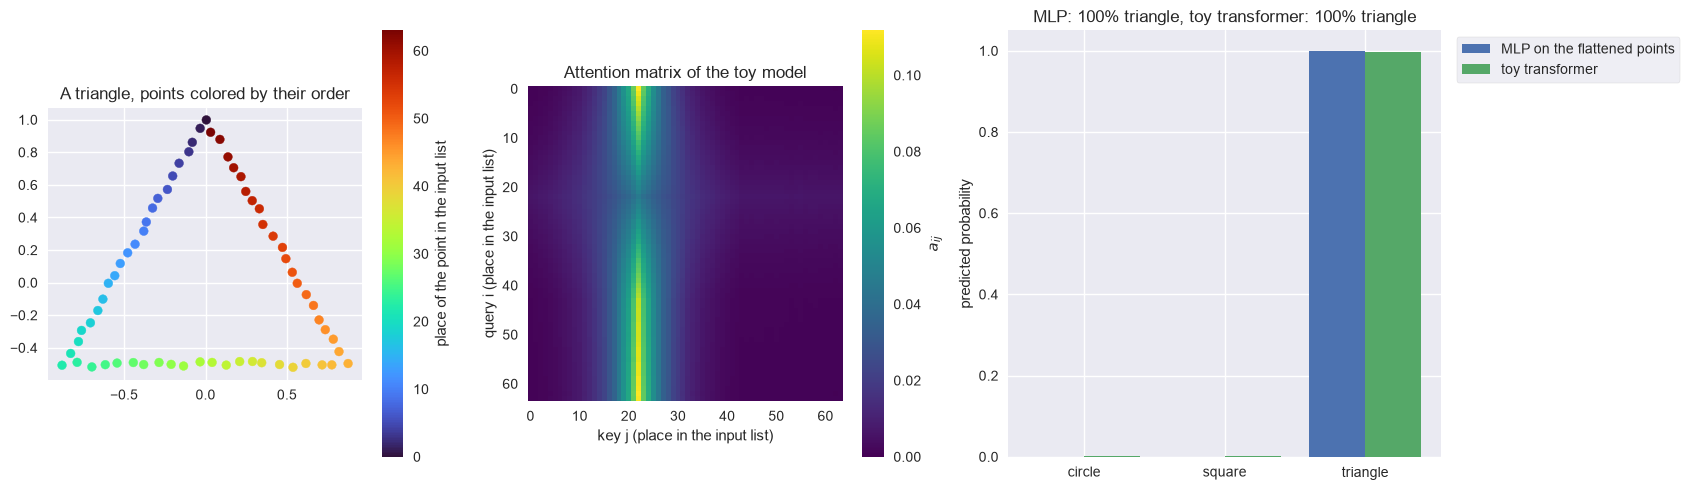

In [100]:
# Interactive: shuffle the order of the points of one shape and compare the MLP from the start of the chapter
# with the toy transformer. The slider needs a running notebook; the book shows the original order.
import ipywidgets as widgets
from IPython.display import display


def live_figure(draw, controls):
    """Show the sliders, then the figure draw(**values), and redraw the figure in place whenever a slider moves."""
    display(widgets.HBox(list(controls.values()), layout=widgets.Layout(flex_flow="row wrap")))
    handle = display(draw(**{name: c.value for name, c in controls.items()}), display_id=True)

    def redraw(change):
        handle.update(draw(**{name: c.value for name, c in controls.items()}))

    for c in controls.values():
        c.observe(redraw, names="value")


def toy_attention(points):
    """Attention weights of the trained toy model for a set of 2D points."""
    block = toy_model.attn_block
    with torch.no_grad():
        embed = toy_model.input_proj(torch.tensor(points, dtype=torch.float32).to(DEVICE))
        scores = block.W_q(embed) @ block.W_k(embed).T / math.sqrt(block.d_model)
        return torch.softmax(scores, dim=-1).cpu().numpy()


shuffle_points = fixed_points[0].numpy()  # one of the fixed-size, ordered 64-point shapes from the first experiment
shuffle_label = SHAPE_TYPES[fixed_labels[0].item()]
mlp_fixed.eval()
toy_model.eval()


def draw_shuffled(shuffle):
    if shuffle == 0:
        order = np.arange(len(shuffle_points))
    else:
        order = np.random.default_rng(shuffle).permutation(len(shuffle_points))
    points = shuffle_points[order]
    x = torch.tensor(points, dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        p_mlp = torch.softmax(mlp_fixed(x.reshape(1, -1)), dim=-1)[0].cpu().numpy()
        p_toy = torch.softmax(toy_model(x[None]), dim=-1)[0].cpu().numpy()
    A_now = toy_attention(points)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
    sc = axes[0].scatter(points[:, 0], points[:, 1], c=np.arange(len(points)), cmap="turbo", s=40)
    fig.colorbar(sc, ax=axes[0], label="place of the point in the input list")
    axes[0].set_aspect("equal")
    axes[0].set_title(f"A {shuffle_label}, points colored by their order")
    im = axes[1].imshow(A_now, cmap="viridis", vmin=0)
    axes[1].grid(False)
    fig.colorbar(im, ax=axes[1], label="$a_{ij}$")
    axes[1].set_xlabel("key j (place in the input list)")
    axes[1].set_ylabel("query i (place in the input list)")
    axes[1].set_title("Attention matrix of the toy model")
    xpos = np.arange(len(SHAPE_TYPES))
    axes[2].bar(xpos - 0.2, p_mlp, 0.4, label="MLP on the flattened points")
    axes[2].bar(xpos + 0.2, p_toy, 0.4, label="toy transformer")
    axes[2].set_xticks(xpos)
    axes[2].set_xticklabels(SHAPE_TYPES)
    axes[2].set_ylim(0, 1.05)
    axes[2].set_ylabel("predicted probability")
    axes[2].set_title(f"MLP: {p_mlp.max():.0%} {SHAPE_TYPES[p_mlp.argmax()]}, "
                      f"toy transformer: {p_toy.max():.0%} {SHAPE_TYPES[p_toy.argmax()]}")
    axes[2].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)
    plt.tight_layout()
    plt.close(fig)
    return fig


live_figure(draw_shuffled, dict(
    shuffle=widgets.IntSlider(value=0, min=0, max=20, description="shuffle", continuous_update=False),
))

### Scaling up to a Full Transformer Encoder

The above example was a single-head, single-layer, low-dimension attention model, so that we could plot everything and gain intuition. However, in practice, we want to use multiple layers and higher-dimensional latent spaces to get good performance. Below we build a larger transformer model (labeled `SetTransformer`) that can be trained on the same 2D shapes dataset, but with more capacity: a CLS token, several stacked attention layers, and a larger $d_\text{model}$. To keep the code short, each layer still uses a single attention head. Real transformers usually run several heads in parallel in each layer, as we described in the "What Is a Transformer?" section.

In [101]:
#| code-fold: false
class SetTransformer(nn.Module):
    def __init__(
        self,
        input_dim: int,
        num_classes: int,
        d_model: int = 64,
        num_layers: int = 3,
        dim_feedforward: int = 128,
        dropout: float = 0.1,
        pooling: str = "cls",
    ):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.layers = nn.ModuleList(
            [SelfAttentionBlock(d_model, dim_feedforward, dropout) for _ in range(num_layers)]
        )
        self.pooling = pooling
        self.classifier = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, num_classes))

    def forward(
        self,
        x: torch.Tensor,
        src_key_padding_mask: Optional[torch.Tensor] = None,
        return_attention: bool = False,
        return_features: bool = False,
    ):
        batch_size = x.size(0)
        proj = self.input_proj(x)
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        tokens = torch.cat([cls_tokens, proj], dim=1)

        if src_key_padding_mask is not None:
            pad = torch.zeros(src_key_padding_mask.size(0), 1, dtype=src_key_padding_mask.dtype, device=src_key_padding_mask.device)
            attn_mask = torch.cat([pad, src_key_padding_mask], dim=1)
        else:
            attn_mask = None

        attention_maps = []
        for layer in self.layers:
            tokens, attn = layer(tokens, key_padding_mask=attn_mask)
            attention_maps.append(attn)

        if self.pooling == "cls":
            features = tokens[:, 0]
        else:
            valid = (~attn_mask[:, 1:]).unsqueeze(-1) if attn_mask is not None else torch.ones_like(tokens[:, 1:])
            summed = (tokens[:, 1:] * valid).sum(dim=1)
            counts = valid.sum(dim=1).clamp_min(1.0)
            features = summed / counts

        logits = self.classifier(features)

        outputs = (logits,)
        if return_attention:
            outputs += (attention_maps,)
        if return_features:
            outputs += (features,)

        if len(outputs) == 1:
            return outputs[0]
        return outputs

Epoch 01/8 | train_loss=1.0379 train_acc=0.476 | val_loss=0.8872 val_acc=0.655
Epoch 02/8 | train_loss=0.5220 train_acc=0.909 | val_loss=0.1528 val_acc=0.998
Epoch 03/8 | train_loss=0.0690 train_acc=0.997 | val_loss=0.0269 val_acc=0.998
Epoch 04/8 | train_loss=0.0206 train_acc=0.999 | val_loss=0.0152 val_acc=0.998
Epoch 05/8 | train_loss=0.0101 train_acc=1.000 | val_loss=0.0091 val_acc=0.999
Epoch 06/8 | train_loss=0.0061 train_acc=1.000 | val_loss=0.0069 val_acc=0.999
Epoch 07/8 | train_loss=0.0042 train_acc=1.000 | val_loss=0.0061 val_acc=0.999
Epoch 08/8 | train_loss=0.0034 train_acc=1.000 | val_loss=0.0059 val_acc=0.999
Noise 0.01 | Transformer accuracy: 99.9%
Epoch 01/8 | train_loss=1.0614 train_acc=0.477 | val_loss=0.9215 val_acc=0.695
Epoch 02/8 | train_loss=0.6362 train_acc=0.818 | val_loss=0.3131 val_acc=0.930
Epoch 03/8 | train_loss=0.1569 train_acc=0.975 | val_loss=0.0651 val_acc=0.994
Epoch 04/8 | train_loss=0.0370 train_acc=0.998 | val_loss=0.0157 val_acc=0.999
Epoch 05/8 

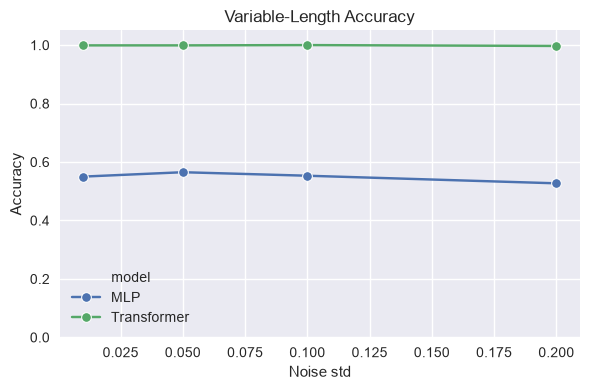

In [102]:
transformer_results = []
transformer_histories = {}

for noise in noise_levels:
    dataset = VariableShapeDataset(num_samples=5000, length_range=(20, 200), noise_std=noise)
    collate_fn = build_variable_collate(dataset.max_points, feature_dim=2)
    train_ds, val_ds = random_split(
        dataset,
        [int(0.8 * len(dataset)), len(dataset) - int(0.8 * len(dataset))],
    )
    train_loader = DataLoader(train_ds, batch_size=192, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, collate_fn=collate_fn)

    transformer = SetTransformer(input_dim=2, num_classes=len(SHAPE_TYPES), d_model=96, num_layers=4)
    optimizer = torch.optim.AdamW(transformer.parameters(), lr=2e-4, weight_decay=1e-4)

    def transformer_forward(model, batch, device):
        return model(batch["points"].to(device), src_key_padding_mask=batch["mask"].to(device))

    history = train_classifier(
        transformer,
        train_loader,
        optimizer,
        criterion,
        epochs=8,
        forward_fn=transformer_forward,
        val_loader=val_loader,
    )
    transformer_histories[noise] = history
    metrics = evaluate_classifier(transformer, val_loader, criterion, forward_fn=transformer_forward)
    transformer_results.append({"model": "Transformer", "noise": noise, "accuracy": metrics["acc"]})
    print(f"Noise {noise:.2f} | Transformer accuracy: {metrics['acc'] * 100:.1f}%")

combined_df = pd.concat([mlp_variable_df, pd.DataFrame(transformer_results)])
plot_metric_curve(combined_df, "Variable-Length Accuracy", hue="model")

## 3D Shapes: Synthetic Point Clouds

In the above examples, we showed a simple 2D shape classification task to build intuition about how transformers work on sets of points. However, the technique is more broadly applicable than this and can be used for more complex problems where something like a 2D or 3D Convolutional Neural Network (CNN) would not be appropriate. In engineering a common task is dealing with point clouds or meshes, and these can often be un-ordered and of variable size, just like in the above case. 

We will demonstrate this on a simple 3D shape classification task using synthetic point clouds. We will vary the density, jitter, and rotations, and also compare Transformers to point-cloud specific architectures like PointNet.

### PointNet vs. Transformer for Point Clouds



Before training the 3D models, it is helpful to review the [**PointNet**](https://arxiv.org/abs/1612.00593) architecture. Like our set transformer, it works on unordered sets of points, and it is a stronger baseline than the MLP we used above.

#### PointNet

Specifically, given a set of 3D points $X = \{p_1, \dots, p_n\}$ with $p_i \in \mathbb{R}^3$, PointNet applies a **shared MLP** to every point and then aggregates with a symmetric pooling function:

$$
\begin{aligned}
h_i &= g(p_i; \theta) \in \mathbb{R}^m, \\
H &= [h_1, \dots, h_n] \in \mathbb{R}^{m \times n}, \\
z &= \text{pool}(H) = \max_i h_i \quad (\text{or mean}), \\
y &= f(z; \phi).
\end{aligned}
$$

Here $g$ and $f$ are small MLPs, and $m$ is the dimension of our model's latent space, which we get to choose. In our implementation:

- $g$ is the 1D-convolutional `shared_mlp` (kernel size 1 = pointwise MLP),

- `torch.max` over points implements the permutation-invariant pooling, and

- `fc` maps the global feature $z$ to class logits.



**Key idea:** permutation invariance is enforced _only_ by the final pooling. Every point is processed independently before pooling, so there is **no explicit message passing between points**.



#### Transformer for point clouds



The set transformer uses almost the opposite design:

- Each point is first embedded into a latent space $h_i = W x_i$.

- Self-attention layers repeatedly **mix information across points** via learned attention weights $a_{ij}$.

- A CLS token or pooling over attended features produces the final global descriptor.



The key difference is what each model knows about a single point before it pools. In PointNet, the feature of point $i$ is
$$
h_i = g(p_i).
$$
It depends only on that point. So, once the model is trained, the same point gets the same feature in every set. After an attention step, the feature is
$$
h_i = x_i + \sum_j a_{ij} v_j .
$$
It depends on the other points too, so the same point gets a different feature in a different set. Only after this does the model pool.

So we expect PointNet to do well when the coarse global shape is enough (e.g., sphere vs. cube), and attention to help when the role of a point depends on the points around it. Attention pays for this with a cost that grows like $N^2$ (Exercise 2). Our four 3D shapes below differ in their coarse global shape, so we expect both models to do well. Exercise 3 builds a task where the difference matters: trays that hold several copies of one part. There, PointNet reaches 69%, and the same PointNet with one attention block in front of it reaches 94%. On trays with one more part than in training, PointNet drops to chance (35%), and the model with attention keeps 88%. This comes from one small model and one training run. A much wider PointNet gets closer on trays with two parts, but not on trays with three.


What we will do now is construct a dataset of 3D point clouds sampled from simple shapes (spheres, cubes, cylinders, pyramids), and then train both a PointNet and a Transformer model on this dataset to compare their performance. Let's first take a look at some example data samples from our synthetic 3D shapes dataset:

In [103]:
SHAPE_TYPES_3D = ["sphere", "cube", "cylinder", "pyramid"]


def random_rotation_matrix() -> np.ndarray:
    angles = np.random.uniform(0, 2 * np.pi, size=3)
    cx, cy, cz = np.cos(angles)
    sx, sy, sz = np.sin(angles)
    rot_x = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    rot_y = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    rot_z = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return rot_z @ rot_y @ rot_x


def generate_3d_shape(shape_type: str, n_points: int, noise_std: float = 0.01) -> np.ndarray:
    """Generate 3D shape point cloud with exactly n_points.

    Fixes previous cube face broadcasting issue by using scalar axis assignment
    with per-face coordinate sampling. Adds safety to enforce exact length.
    """
    if shape_type not in SHAPE_TYPES_3D:
        raise ValueError(shape_type)

    if shape_type == "sphere":
        phi = np.random.uniform(0, 2 * np.pi, size=n_points)
        costheta = np.random.uniform(-1, 1, size=n_points)
        theta = np.arccos(costheta)
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        points = np.stack([x, y, z], axis=1)

    elif shape_type == "cube":
        # Choose a face for each point: 0:+x,1:-x,2:+y,3:-y,4:+z,5:-z
        faces = np.random.choice(6, size=n_points)
        # For each point we need two free coordinates in [-1,1]
        free = np.random.uniform(-1, 1, size=(n_points, 2))
        points = np.zeros((n_points, 3))
        for face in range(6):
            mask = faces == face
            if not mask.any():
                continue
            m = mask.sum()
            if face == 0:  # +x face
                points[mask, 0] = 1.0
                points[mask, 1] = free[mask, 0]
                points[mask, 2] = free[mask, 1]
            elif face == 1:  # -x face
                points[mask, 0] = -1.0
                points[mask, 1] = free[mask, 0]
                points[mask, 2] = free[mask, 1]
            elif face == 2:  # +y face
                points[mask, 1] = 1.0
                points[mask, 0] = free[mask, 0]
                points[mask, 2] = free[mask, 1]
            elif face == 3:  # -y face
                points[mask, 1] = -1.0
                points[mask, 0] = free[mask, 0]
                points[mask, 2] = free[mask, 1]
            elif face == 4:  # +z face
                points[mask, 2] = 1.0
                points[mask, 0] = free[mask, 0]
                points[mask, 1] = free[mask, 1]
            elif face == 5:  # -z face
                points[mask, 2] = -1.0
                points[mask, 0] = free[mask, 0]
                points[mask, 1] = free[mask, 1]

    elif shape_type == "cylinder":
        angles = np.random.uniform(0, 2 * np.pi, size=n_points)
        heights = np.random.uniform(-1, 1, size=n_points)
        x = np.cos(angles)
        y = np.sin(angles)
        z = heights
        points = np.stack([x, y, z], axis=1)

    else:  # hollow pyramid with points sampled on each side
        # Define pyramid vertices: apex at (0, 0, 1), square base at z = -1
        apex = np.array([0.0, 0.0, 1.0])
        base_vertices = np.array([
            [1.0, 1.0, -1.0],
            [-1.0, 1.0, -1.0],
            [-1.0, -1.0, -1.0],
            [1.0, -1.0, -1.0]
        ])
        
        # Distribute points across 4 triangular side faces + square base
        n_faces = 5
        base_count = n_points // n_faces
        rem = n_points % n_faces
        counts = [base_count + (i < rem) for i in range(n_faces)]
        
        face_points = []
        
        # Sample points on each triangular side face (apex to two base corners)
        for i in range(4):
            n_face = counts[i]
            if n_face == 0:
                continue
            v1 = base_vertices[i]
            v2 = base_vertices[(i + 1) % 4]
            # Barycentric coordinates for triangle (apex, v1, v2)
            u = np.random.uniform(0, 1, size=n_face)
            v = np.random.uniform(0, 1, size=n_face)
            # Fold triangle: if u + v > 1, reflect to other half
            mask = (u + v) > 1
            u[mask] = 1 - u[mask]
            v[mask] = 1 - v[mask]
            w = 1 - u - v
            pts = (w[:, None] * apex + 
                u[:, None] * v1 + 
                v[:, None] * v2)
            face_points.append(pts)
        
        # Sample points uniformly on the square base face
        n_base = counts[4]
        if n_base > 0:
            # Uniform sampling on the square at z = -1, x in [-1, 1], y in [-1, 1]
            base_x = np.random.uniform(-1, 1, size=n_base)
            base_y = np.random.uniform(-1, 1, size=n_base)
            base_z = np.full(n_base, -1.0)
            base_pts = np.stack([base_x, base_y, base_z], axis=1)
            face_points.append(base_pts)
        
        points = np.concatenate(face_points, axis=0) if face_points else np.zeros((0, 3))
        

    # Add noise and random rotation
    points += np.random.normal(scale=noise_std, size=points.shape)
    points = points @ random_rotation_matrix().T

    # Safety: enforce exact length (already ensured but keep consistency with 2D generator)
    if points.shape[0] != n_points:
        if points.shape[0] > n_points:
            points = points[:n_points]
        else:
            extra_idx = np.random.choice(points.shape[0], n_points - points.shape[0], replace=True)
            points = np.concatenate([points, points[extra_idx]], axis=0)
    return points


class SyntheticPointCloudDataset(Dataset):
    def __init__(self, num_samples: int = 3000, length_range: Tuple[int, int] = (200, 1000), noise_std: float = 0.02):
        self.samples: List[torch.Tensor] = []
        self.labels: List[int] = []
        self.max_points = length_range[1]
        for _ in range(num_samples):
            label = random.randrange(len(SHAPE_TYPES_3D))
            n_points = random.randint(*length_range)
            pts = generate_3d_shape(SHAPE_TYPES_3D[label], n_points=n_points, noise_std=noise_std)
            self.samples.append(torch.tensor(pts, dtype=torch.float32))
            self.labels.append(label)

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        return {"points": self.samples[idx], "labels": torch.tensor(self.labels[idx], dtype=torch.long)}


def build_pointcloud_collate(max_points: int, dims: int = 3):
    def collate(batch: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
        batch_size = len(batch)
        padded = torch.zeros(batch_size, max_points, dims)
        mask = torch.ones(batch_size, max_points, dtype=torch.bool)
        labels = torch.zeros(batch_size, dtype=torch.long)
        for i, item in enumerate(batch):
            pts = item["points"]
            n = min(pts.size(0), max_points)
            padded[i, :n] = pts[:n]
            mask[i, :n] = False
            labels[i] = item["labels"]
        flat = padded.reshape(batch_size, -1)
        return {"points": padded, "mask": mask, "inputs": flat, "labels": labels}

    return collate

In [104]:
set_seed(42)  # the 3D results below do not depend on the random numbers used above
cloud_dataset = SyntheticPointCloudDataset(num_samples=3200, length_range=(256, 1024), noise_std=0.002)
collate_cloud = build_pointcloud_collate(cloud_dataset.max_points, dims=3)
train_cloud, val_cloud = random_split(
    cloud_dataset,
    [int(0.75 * len(cloud_dataset)), len(cloud_dataset) - int(0.75 * len(cloud_dataset))],
)
train_loader_cloud = DataLoader(train_cloud, batch_size=64, shuffle=True, collate_fn=collate_cloud)
val_loader_cloud = DataLoader(val_cloud, batch_size=128, shuffle=False, collate_fn=collate_cloud)

# Interactive demo (set interactive=True)
for idx in np.random.choice(len(cloud_dataset), size=3, replace=False):
    pts = cloud_dataset[idx]["points"].numpy()
    label = SHAPE_TYPES_3D[cloud_dataset.labels[idx]]
    scatter_3d_points(pts, f"Example {label}", interactive=True)

In [105]:
#| code-fold: false
class PointNetClassifier(nn.Module):
    def __init__(self, input_dim: int = 3, widths: Tuple[int, ...] = (64, 128, 256), num_classes: int = 4, dropout: float = 0.3):
        super().__init__()
        layers: List[nn.Module] = []
        dims = [input_dim, *widths]
        for in_dim, out_dim in zip(dims[:-1], dims[1:]):
            layers.append(nn.Conv1d(in_dim, out_dim, kernel_size=1))
            layers.append(nn.BatchNorm1d(out_dim))
            layers.append(nn.ReLU())
        self.shared_mlp = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(widths[-1], 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor, return_features: bool = False):
        x = x.transpose(1, 2)
        features = self.shared_mlp(x)
        pooled = torch.max(features, dim=2).values
        logits = self.fc(self.dropout(pooled))
        if return_features:
            return logits, pooled
        return logits

In [106]:
#| code-fold: false
mlp_cloud = ShapeMLP(input_dim=cloud_dataset.max_points * 3, hidden_dims=(16, 16, 16), num_classes=len(SHAPE_TYPES_3D))
# No dropout: with only 16 pooled features, dropping 30% of them at every step
# keeps this small PointNet from fitting even the training set.
pointnet = PointNetClassifier(num_classes=len(SHAPE_TYPES_3D), widths=(16, 16, 16), dropout=0.0)
transformer_cloud = SetTransformer(
    input_dim=3,
    num_classes=len(SHAPE_TYPES_3D),
    d_model=15,
    num_layers=3,
    dim_feedforward=20,
    dropout=0.0,  # like PointNet, this small model does not need dropout
)


def pointnet_forward(model, batch, device):
    return model(batch["points"].to(device))


def transformer_cloud_forward(model, batch, device):
    return model(batch["points"].to(device), src_key_padding_mask=batch["mask"].to(device))


models_cloud = {
    "MLP": (mlp_cloud, mlp_forward),
    "PointNet": (pointnet, pointnet_forward),
    "Transformer": (transformer_cloud, transformer_cloud_forward),
}

# Print the parameter counts for each of the models in models_cloud:
for name, (model, _) in models_cloud.items():
    param_count = sum(p.numel() for p in model.parameters())
    print(f"{name} parameter count: {param_count:,}")


MLP parameter count: 49,780
PointNet parameter count: 6,084
Transformer parameter count: 4,099


In [107]:

cloud_histories = {}
cloud_metrics = []

for name, (model, forward_fn) in models_cloud.items():
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4 if name != "Transformer" else 3e-3, weight_decay=1e-4)
    history = train_classifier(
        model,
        train_loader_cloud,
        optimizer,
        criterion,
        epochs=15,
        forward_fn=forward_fn,
        val_loader=val_loader_cloud,
    )
    cloud_histories[name] = history
    metrics = evaluate_classifier(model, val_loader_cloud, criterion, forward_fn=forward_fn)
    cloud_metrics.append({"model": name, "accuracy": metrics["acc"]})
    print(f"{name} accuracy: {metrics['acc'] * 100:.1f}%")


Epoch 01/15 | train_loss=1.3978 train_acc=0.253 | val_loss=1.3842 val_acc=0.245
Epoch 02/15 | train_loss=1.3791 train_acc=0.334 | val_loss=1.3615 val_acc=0.426
Epoch 03/15 | train_loss=1.3084 train_acc=0.402 | val_loss=1.2530 val_acc=0.336
Epoch 04/15 | train_loss=1.1712 train_acc=0.357 | val_loss=1.1494 val_acc=0.361
Epoch 05/15 | train_loss=1.0604 train_acc=0.453 | val_loss=1.1007 val_acc=0.426
Epoch 06/15 | train_loss=0.9667 train_acc=0.537 | val_loss=1.0913 val_acc=0.453
Epoch 07/15 | train_loss=0.8701 train_acc=0.649 | val_loss=1.1061 val_acc=0.481
Epoch 08/15 | train_loss=0.7541 train_acc=0.700 | val_loss=1.1396 val_acc=0.492
Epoch 09/15 | train_loss=0.6397 train_acc=0.726 | val_loss=1.1955 val_acc=0.487
Epoch 10/15 | train_loss=0.5353 train_acc=0.787 | val_loss=1.2771 val_acc=0.482
Epoch 11/15 | train_loss=0.4552 train_acc=0.885 | val_loss=1.3495 val_acc=0.476
Epoch 12/15 | train_loss=0.3822 train_acc=0.902 | val_loss=1.4299 val_acc=0.481
Epoch 13/15 | train_loss=0.3137 train_ac

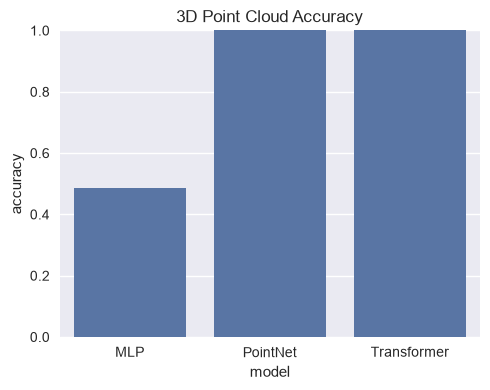

In [108]:

cloud_metrics_df = pd.DataFrame(cloud_metrics)
plt.figure(figsize=(5, 4))
sns.barplot(data=cloud_metrics_df, x="model", y="accuracy")
plt.ylim(0, 1)
plt.title("3D Point Cloud Accuracy")
plt.tight_layout()

In [109]:
transformer_ref = models_cloud["Transformer"][0]
embeddings = []
labels = []
with torch.no_grad():
    for batch in val_loader_cloud:
        logits, features = transformer_ref(
            batch["points"].to(DEVICE),
            src_key_padding_mask=batch["mask"].to(DEVICE),
            return_features=True,
        )
        embeddings.append(features.cpu())
        labels.append(batch["labels"])
embeddings = torch.cat(embeddings).numpy()
labels = torch.cat(labels).numpy()
visualize_embeddings(embeddings, labels, SHAPE_TYPES_3D, "Transformer embeddings", method="pca", dim=3)

batch = next(iter(val_loader_cloud))
logits, attn_maps, _ = transformer_ref(
    batch["points"].to(DEVICE),
    src_key_padding_mask=batch["mask"].to(DEVICE),
    return_attention=True,
    return_features=True,
)
batch_idx = 6  # Visualize this sample in batch
# attn_maps[-1] has shape (B, N, N) where N includes the CLS token
# We want attention from CLS token (index 0) to actual points (indices 1:)
attn_cls = attn_maps[-1][batch_idx, 0, 1:].detach().cpu().numpy()
mask = batch["mask"][batch_idx].numpy()
valid_points = batch["points"][batch_idx][~mask].numpy()
attn_cls = attn_cls[: valid_points.shape[0]]
print(
    f"CLS attention weights: largest {attn_cls.max():.4f}, smallest {attn_cls.min():.2e}, "
    f"uniform would be {1 / len(attn_cls):.4f}"
)
scatter_3d_points(valid_points, f"Attention heatmap ({SHAPE_TYPES_3D[batch['labels'][batch_idx].item()]})", colors=attn_cls, interactive=True)

CLS attention weights: largest 0.0043, smallest 4.05e-04, uniform would be 0.0016


In 3D, the CLS token of the last layer does not give every point the same weight. For this cylinder, the largest weight (0.0043) is almost three times the uniform weight (0.0016), and the smallest (0.0004) is about a quarter of it. The heatmap shows the raw weights.

## Summary

In this chapter we built attention on unordered point sets and compared three ways to classify such a set.

- **MLP on the flattened points.** It reads each point by its place in the input vector. This works when every set has the same number of points in the same order (our first 2D experiment). It fails when the order or the number of points changes (about 55% in the variable-length experiment).
- **PointNet.** It applies the same small MLP to every point on its own and then pools with a max. Pooling makes it independent of the order and the number of points, and its cost grows like $N$. The feature of a point depends only on that point. So PointNet does well when the coarse global shape is enough, as for our 3D shapes (100%). It struggled on the trays of Exercise 3, where the points of each part have to be found first (35% on trays with three parts).
- **Attention.** Each point gathers information from the other points before pooling, with weights $a_{ij}$ that depend on the data. The queries and keys set the weights, and the values carry what is passed on. The size of the scores sets how sharp the weights are, from a plain average over the points to a lookup of one point. The residual connection lets each point keep its own features. Attention stayed above 99% in the 2D experiment and reached 100% on our 3D shapes. Its cost grows like $N^2$ (Exercise 2). That is fine for a few hundred points and far too much for a full scan of a part.

Attention also surprised us in a few ways:

- The learned attention was not local. In the toy model, every row of $A$ has its largest weight in the same column: every point listens most to the same point.
- Attention that is too flat or too sharp throws information away. With a small factor on the scores, every point receives nearly the same average. With a large factor, each point copies a single other point. In our toy model all points rank the same point first, so they all copy that one point.
- On our 3D shapes, PointNet did as well as the transformer at a lower cost. Attention pays off only when the task needs the points to be compared with each other.

So a reasonable order is: use an MLP when the input has a fixed order and size, PointNet when the global shape of an unordered set is enough, and attention when the points need to be compared with each other and the set is small enough to pay for it.

## Exercises

These exercises use the chapter's models and data, so run the chapter's cells first. Each title gives a rough time estimate.

Exercise 1 looks at the division by $\sqrt{d_k}$ in the attention weights $a_{ij} = \text{softmax}_j\left(q_i^\top k_j / \sqrt{d_k}\right)$. We will write $d$ for $d_k$, just to simplify notation. The cell below draws random queries $q$ and keys $k$ whose entries are independent standard normal numbers, $\mathcal{N}(0, 1)$, for $d$ = 2, 16, 128 and 1024. It compares the raw scores $q^\top k$ with the scaled scores $q^\top k / \sqrt{d}$. It makes four panels:

- A: the standard deviation of the score over 20,000 random pairs $(q, k)$.
- B, C and D: one query against 50 keys, averaged over 500 queries. B shows the largest of the 50 weights. C shows the entropy $-\sum_j a_j \ln a_j$ of the weights. It is $\ln 50 \approx 3.9$ when all weights are equal and 0 when one weight is 1. D shows the size (Frobenius norm) of the softmax Jacobian $\partial a_i / \partial s_j$, where $s_j$ is the score of key $j$. It measures how much the weights change when the scores change.

You can change the list of dimensions at the top of the cell and re-run it.

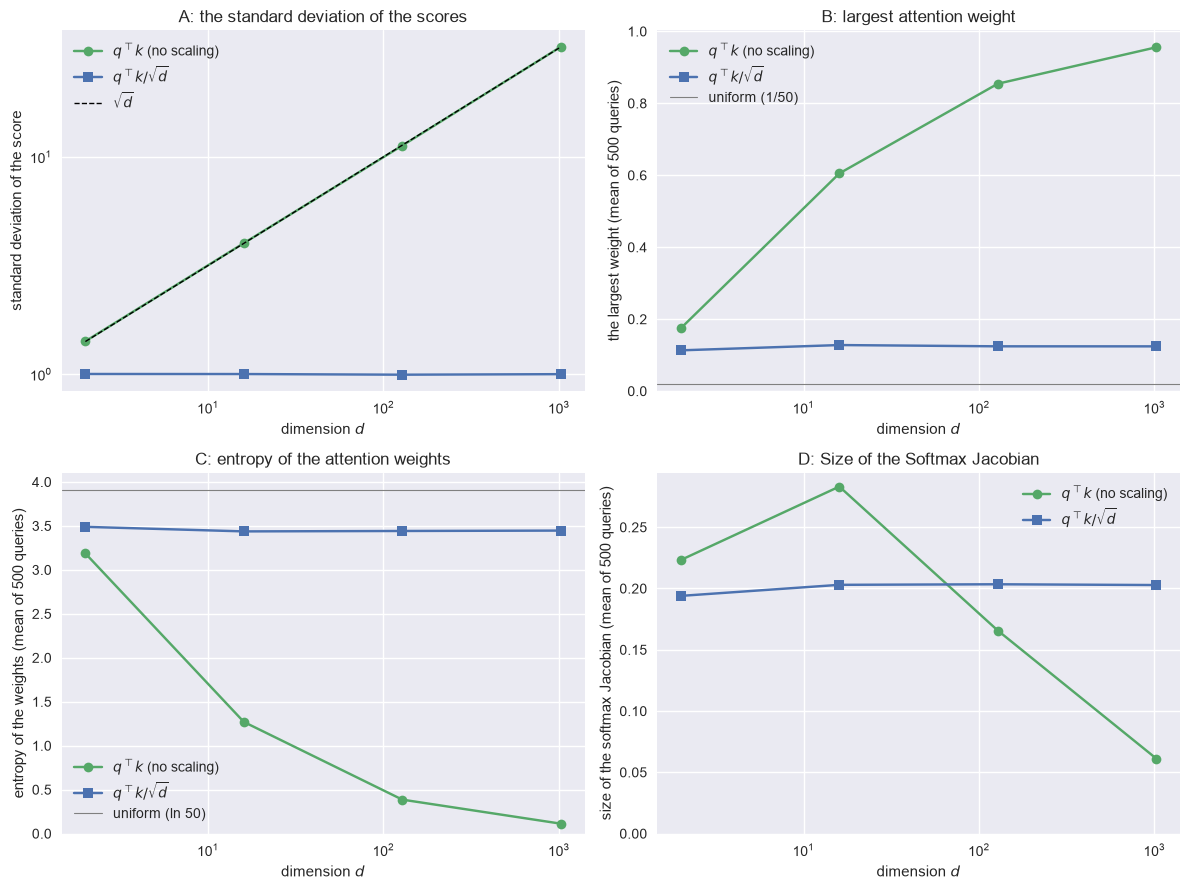

Standard deviation of q.k: d = 2: 1.42, d = 16: 4.01, d = 128: 11.26, d = 1024: 32.04
Standard deviation of q.k / sqrt(d): d = 2: 1.00, d = 16: 1.00, d = 128: 1.00, d = 1024: 1.00
No scaling: d = 2: largest 0.17, entropy 3.19, Jacobian 0.223; d = 16: largest 0.61, entropy 1.27, Jacobian 0.283; d = 128: largest 0.85, entropy 0.39, Jacobian 0.166; d = 1024: largest 0.96, entropy 0.11, Jacobian 0.061
Divided by sqrt(d): d = 2: largest 0.11, entropy 3.49, Jacobian 0.194; d = 16: largest 0.13, entropy 3.44, Jacobian 0.203; d = 128: largest 0.12, entropy 3.44, Jacobian 0.203; d = 1024: largest 0.12, entropy 3.45, Jacobian 0.203


In [110]:
#| echo: false
# Figure for Exercise 1: why the attention scores are divided by sqrt(d_k). No training, only random vectors.
EX1_DIMS = [2, 16, 128, 1024]   # key dimensions d_k to compare; feel free to change them
EX1_KEYS = 50                   # keys per query
EX1_QUERIES = 500               # queries per dimension; the panels show averages over these
EX1_SEED = 0
ex1_rng = np.random.default_rng(EX1_SEED)


def ex1_softmax(s):
    e = np.exp(s - s.max())
    return e / e.sum()


def ex1_weight_stats(a):
    """Largest weight, entropy, and the size of the softmax Jacobian diag(a) - a a^T."""
    entropy = -np.sum(a * np.log(a + 1e-300))
    jacobian = np.diag(a) - np.outer(a, a)
    return a.max(), entropy, np.linalg.norm(jacobian)


# (a) spread of q.k for random q and k with independent N(0, 1) entries
ex1_spread = {"raw": [], "scaled": []}
for d in EX1_DIMS:
    q = ex1_rng.standard_normal((20000, d))
    k = ex1_rng.standard_normal((20000, d))
    dots = np.sum(q * k, axis=1)
    ex1_spread["raw"].append(dots.std())
    ex1_spread["scaled"].append((dots / np.sqrt(d)).std())

# (b) one query against EX1_KEYS keys, with and without the division by sqrt(d)
ex1_stats = {"raw": [], "scaled": []}
for d in EX1_DIMS:
    rows = {"raw": [], "scaled": []}
    for t in range(EX1_QUERIES):
        q = ex1_rng.standard_normal(d)
        K = ex1_rng.standard_normal((EX1_KEYS, d))
        s = K @ q
        for name, scores in [("raw", s), ("scaled", s / np.sqrt(d))]:
            a = ex1_softmax(scores)
            rows[name].append(ex1_weight_stats(a))
    for name in rows:
        ex1_stats[name].append(np.mean(rows[name], axis=0))
ex1_stats = {name: np.array(v) for name, v in ex1_stats.items()}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
dims = np.array(EX1_DIMS)
styles = {"raw": ("o-", "C1", r"$q^\top k$ (no scaling)"), "scaled": ("s-", "C0", r"$q^\top k / \sqrt{d}$")}

ax = axes[0, 0]
for name, (fmt, color, label) in styles.items():
    ax.loglog(dims, ex1_spread[name], fmt, color=color, label=label)
ax.loglog(dims, np.sqrt(dims), "k--", lw=1, label=r"$\sqrt{d}$")
ax.set_xlabel("dimension $d$")
ax.set_ylabel("standard deviation of the score")
ax.set_title("A: the standard deviation of the scores")
ax.legend()

panels = [
    (axes[0, 1], 0, "the largest weight", "B: largest attention weight", 1 / EX1_KEYS, "uniform (1/50)"),
    (axes[1, 0], 1, "entropy of the weights", "C: entropy of the attention weights", np.log(EX1_KEYS), "uniform (ln 50)"),
    (axes[1, 1], 2, "size of the softmax Jacobian", "D: Size of the Softmax Jacobian", None, None),
]
for ax, col, ylabel, title, ref, ref_label in panels:
    for name, (fmt, color, label) in styles.items():
        ax.semilogx(dims, ex1_stats[name][:, col], fmt, color=color, label=label)
    if ref is not None:
        ax.axhline(ref, color="gray", lw=0.8, label=ref_label)
    ax.set_xlabel("dimension $d$")
    ax.set_ylabel(ylabel + f" (mean of {EX1_QUERIES} queries)")
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.legend()

plt.tight_layout()
plt.show()

print("Standard deviation of q.k:", ", ".join(f"d = {d}: {s:.2f}" for d, s in zip(EX1_DIMS, ex1_spread["raw"])))
print("Standard deviation of q.k / sqrt(d):", ", ".join(f"d = {d}: {s:.2f}" for d, s in zip(EX1_DIMS, ex1_spread["scaled"])))
for name in ["raw", "scaled"]:
    print(f"{'No scaling' if name == 'raw' else 'Divided by sqrt(d)'}: " + "; ".join(
        f"d = {d}: largest {m:.2f}, entropy {h:.2f}, Jacobian {j:.3f}" for d, (m, h, j) in zip(EX1_DIMS, ex1_stats[name])))

::: {.callout-note appearance="simple" icon=false}
### Exercise 1 (~10 min): Why divide by $\sqrt{d_k}$?
The chapter says that the division by $\sqrt{d_k}$ keeps the softmax away from regions with very small gradients. The figure above tests this claim with random vectors.

- (a) In panel A, the spread of $q^\top k$ grows like $\sqrt{d}$. Why? Why does the division by $\sqrt{d}$ keep it at 1 for every $d$?
- (b) Look at panels B, C and D. What does attention do at large $d$ without the scaling? Why does this make $W_Q$ and $W_K$ hard to learn with gradient descent?
- (c) In panel D, the curve without scaling lies above the scaled curve at $d$ = 2 and 16, and below it only at large $d$. Why? If the scaling does not always give larger gradients, why do transformers use it?
:::

---

For Exercise 2 we timed the chapter's 3D-sized models: the `SetTransformer` with $d_\text{model}$ = 15 and 3 layers, and the `PointNetClassifier` with widths 16, 16, 16. Each forward pass takes a batch of 8 random sets with $N$ points each, for $N$ = 128 to 4096. We kept the fastest of 15 runs on one CPU thread. We also recorded how much GPU memory one forward pass needs at its peak. A set with a single point already needs about 1 MB, so we subtracted that amount. The timings take a few minutes and depend on the computer, so the cell below loads our measurements from `data/transformers_cost.csv`. It plots them on log-log axes, with gray guide lines of slope 1 and 2.

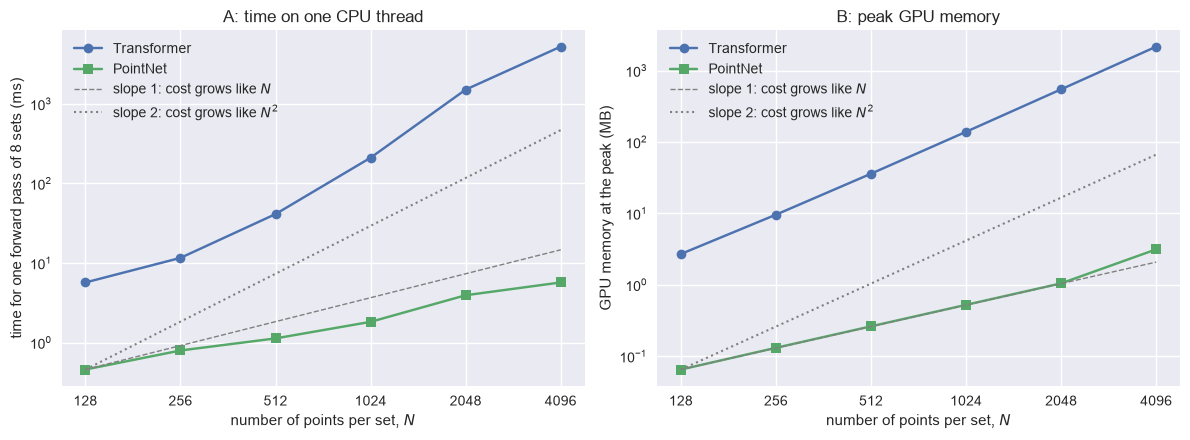

      model  n_points  cpu_time_ms   gpu_mb
Transformer       128        5.693    2.700
Transformer       256       11.601    9.598
Transformer       512       41.203   35.979
Transformer      1024      210.560  139.071
Transformer      2048     1512.363  547.236
Transformer      4096     5250.792 2168.219
   PointNet       128        0.458    0.065
   PointNet       256        0.795    0.131
   PointNet       512        1.128    0.262
   PointNet      1024        1.822    0.524
   PointNet      2048        3.934    1.048
   PointNet      4096        5.700    3.136


In [111]:
#| echo: false
# Figure for Exercise 2: measured cost of one forward pass against the number of points N
# Precomputed timings of the chapter's 3D-sized models (one CPU thread, fastest of 15 runs),
# and their peak GPU memory minus what a set with a single point already needs
COST_CSV = "../../data/transformers_cost.csv"
# If you don't have the data folder locally (for example on Google Colab), load the GitHub copy instead:
# COST_CSV = "https://raw.githubusercontent.com/IDEALLab/ML4ME_Textbook/main/data/transformers_cost.csv"
cost = pd.read_csv(COST_CSV)
cost_models = [("Transformer", "o-", "C0"), ("PointNet", "s-", "C1")]
n_ref = np.array([128, 4096], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column, ylabel, title in [
    (axes[0], "cpu_time_ms", "time for one forward pass of 8 sets (ms)", "A: time on one CPU thread"),
    (axes[1], "gpu_mb", "GPU memory at the peak (MB)", "B: peak GPU memory"),
]:
    for name, fmt, color in cost_models:
        sub = cost[cost.model == name]
        ax.loglog(sub.n_points, sub[column], fmt, color=color, label=name)
    # Gray guide lines with slope 1 and slope 2, to compare the curves against
    y0 = cost[column].min()
    ax.loglog(n_ref, y0 * (n_ref / n_ref[0]), "--", color="gray", lw=1, label="slope 1: cost grows like $N$")
    ax.loglog(n_ref, y0 * (n_ref / n_ref[0]) ** 2, ":", color="gray", lw=1.5, label="slope 2: cost grows like $N^2$")
    ax.set_xlabel("number of points per set, $N$")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(cost.n_points.unique()))
    ax.set_xticklabels([str(n) for n in sorted(cost.n_points.unique())])
    ax.minorticks_off()
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()
print(cost.to_string(index=False))

::: {.callout-note appearance="simple" icon=false}
### Exercise 2 (~10 min): How the cost grows with the number of points
On log-log axes, a cost that grows like $N^p$ is a straight line with slope $p$.

- (a) Read off the slope of each curve in both panels for $N \geq 512$. Which step of each model sets its slope, and why? Which panel follows a straight line more closely, and why? If we double $N$, about how much longer does each forward pass take for each model, and why?
- (b) A laser scan of a real part has about 100,000 points. Starting from the measurement at $N$ = 4096, use your slope to estimate the time of one transformer forward pass on a batch of 8 such scans. Then estimate the memory of one attention matrix for one set and one layer, with 4 bytes per number. Why is this a problem for training? What would you do instead?
:::

---

For Exercise 3 we built trays that hold two or three copies of one part. The part is the outline of a circle, a square or a triangle, at a random place, size and angle. Each tray is a set of 48 points in random order, and the task is to say which part is on the tray. We trained four models on 10,000 trays with two parts:

- the chapter's MLP on the flattened points,
- the chapter's PointNet,
- PointNet with one of the chapter's attention blocks in front of it,
- the same, but with uniform attention: every point gives the same weight, $1/48$, to every point.

We tested them on new trays with two parts and on trays with three parts, which no model saw in training. Training takes a few minutes, so the cell below loads our results from `data/transformers_trays.npz`. Panel A shows example trays, and panel B the test accuracy. Panel C shows one tray with three parts: on the left, the weights that one point (red circle) gives to the other points; in the middle, the part each point belongs to; on the right, the part that gets most of each point's weight.

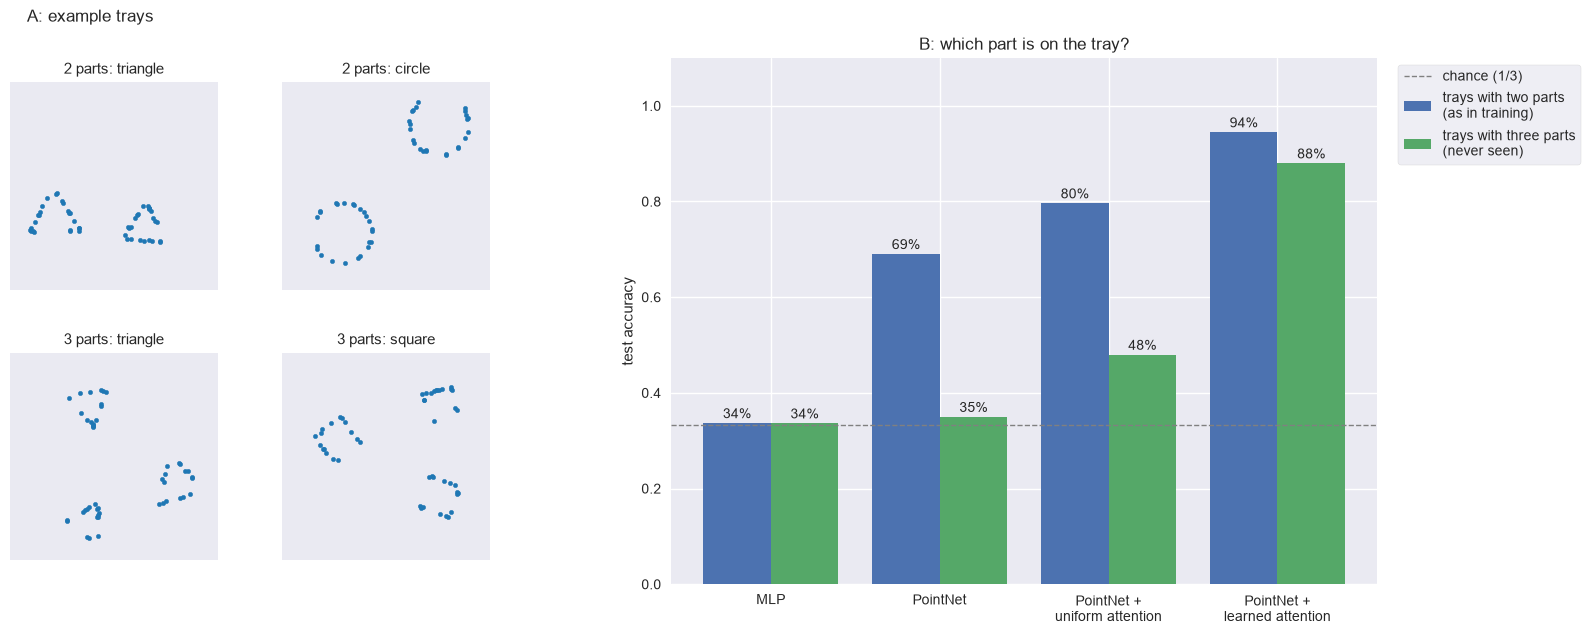

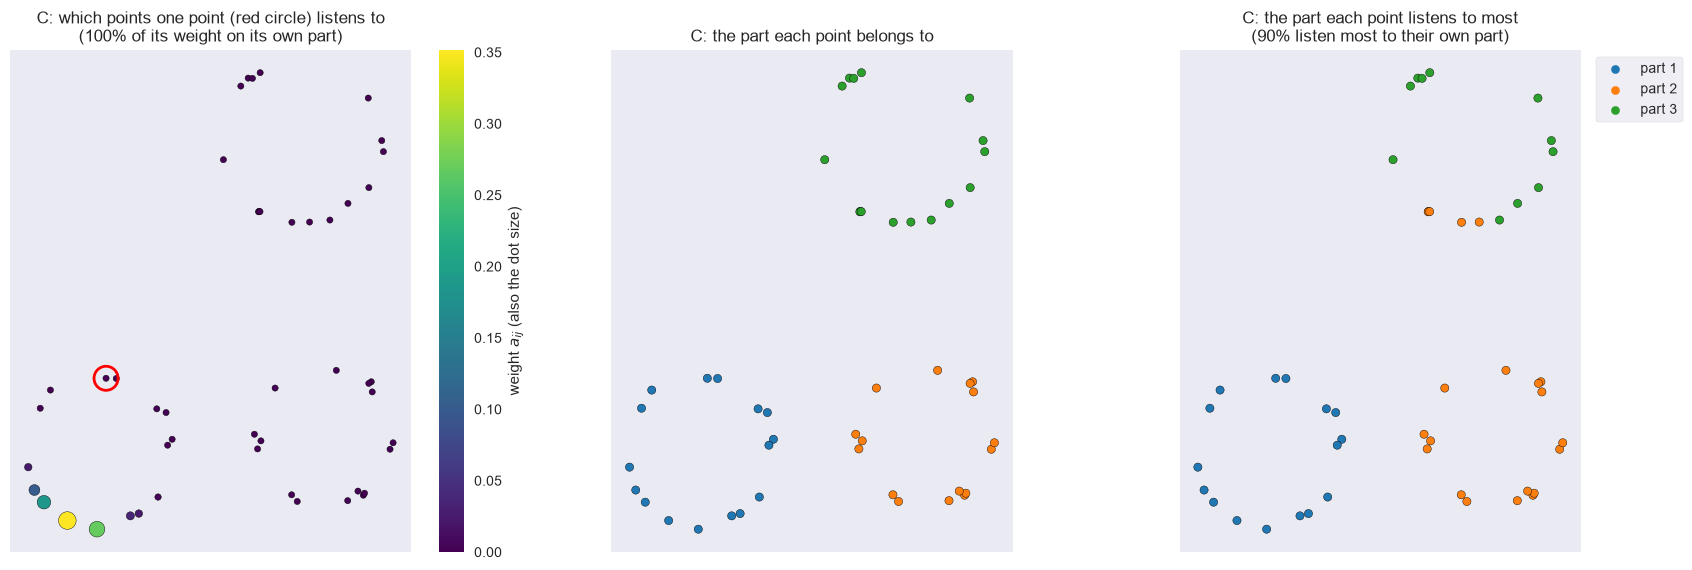

Share of a point's weight that lands on its own part, over 500 trays:
  two parts: 0.95 (chance 0.50)
  three parts: 0.90 (chance 0.33)


In [112]:
#| echo: false
# Figure for Exercise 3: trays with two or three copies of one part (precomputed results)
trays = np.load("../../data/transformers_trays.npz")
model_names = [str(n) for n in trays["model_names"]]
part_names = ["circle", "square", "triangle"]

# Panels A and B: example trays and accuracies
fig = plt.figure(figsize=(16, 6.5))
grid = fig.add_gridspec(2, 4, width_ratios=[1, 1, 0.25, 3.4])
examples = [("examples_two", "labels_two", 0, 2), ("examples_two", "labels_two", 1, 2),
            ("examples_three", "labels_three", 0, 3), ("examples_three", "labels_three", 1, 3)]
for k, (key, label_key, idx, n_parts) in enumerate(examples):
    ax = fig.add_subplot(grid[k // 2, k % 2])
    tray = trays[key][idx]
    ax.scatter(tray[:, 0], tray[:, 1], s=10, c="tab:blue")
    ax.set_title(f"{n_parts} parts: {part_names[trays[label_key][idx]]}", fontsize=11)
    ax.set_aspect("equal")
    ax.set_xlim(-3.4, 3.4)
    ax.set_ylim(-3.4, 3.4)
    ax.set_xticks([])
    ax.set_yticks([])
fig.text(0.02, 0.97, "A: example trays", fontsize=12, va="top")
ax = fig.add_subplot(grid[:, 3])
x = np.arange(len(model_names))
bars_two = ax.bar(x - 0.2, trays["acc_two"], 0.4, label="trays with two parts\n(as in training)")
bars_three = ax.bar(x + 0.2, trays["acc_three"], 0.4, label="trays with three parts\n(never seen)")
for bar in list(bars_two) + list(bars_three):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.0%}", ha="center", fontsize=10)
ax.axhline(1 / 3, color="gray", ls="--", lw=1, label="chance (1/3)")
ax.set_xticks(x)
ax.set_xticklabels([name.replace("PointNet with\n", "PointNet +\n") for name in model_names], fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_ylabel("test accuracy")
ax.set_title("B: which part is on the tray?")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

# Panel C: where the points listen to, in one tray with three parts (the learned attention block)
tray = 14
points, ids, A_tray = trays["trays_three"][tray], trays["ids_three"][tray], trays["attention_three"][tray]
members = np.where(ids == 0)[0]
own_shares = A_tray[members][:, ids == 0].sum(axis=1)
query = members[np.argsort(own_shares)[len(members) // 2]]  # a typical point: median share on its own part
listens_to = np.argmax([A_tray[:, ids == part].sum(axis=1) for part in range(3)], axis=0)
part_colors = np.array(["tab:blue", "tab:orange", "tab:green"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
sc = axes[0].scatter(points[:, 0], points[:, 1], c=A_tray[query], cmap="viridis", vmin=0, s=20 + 400 * A_tray[query],
                     edgecolors="k", linewidths=0.3, zorder=3)
axes[0].scatter(*points[query], s=300, facecolors="none", edgecolors="red", linewidths=2, zorder=4)
fig.colorbar(sc, ax=axes[0], label=r"weight $a_{ij}$ (also the dot size)")
axes[0].set_title(f"C: which points one point (red circle) listens to\n({A_tray[query, ids == 0].sum():.0%} of its weight on its own part)")
axes[1].scatter(points[:, 0], points[:, 1], c=part_colors[ids], s=35, edgecolors="k", linewidths=0.3)
axes[1].set_title("C: the part each point belongs to")
axes[2].scatter(points[:, 0], points[:, 1], c=part_colors[listens_to], s=35, edgecolors="k", linewidths=0.3)
axes[2].set_title(f"C: the part each point listens to most\n({np.mean(listens_to == ids):.0%} listen most to their own part)")
for part in range(3):
    axes[2].scatter([], [], c=part_colors[part], s=35, label=f"part {part + 1}")
axes[2].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
print("Share of a point's weight that lands on its own part, over 500 trays:")
print(f"  two parts: {trays['share_two']:.2f} (chance 0.50)")
print(f"  three parts: {trays['share_three']:.2f} (chance 0.33)")

::: {.callout-note appearance="simple" icon=false}
### Exercise 3 (~15 min): What does one attention block add to PointNet?
- (a) PointNet computes a feature for each point from that point alone, and then takes the largest value of each feature over the tray. If the same point appears in two different trays, does PointNet give it the same feature? Why does this make it hard for PointNet to tell which points belong to the same part? Why does PointNet then do worse than the model with attention in panel B?
- (b) In panel C, which part does each point give most of its weight to? What does $z_i$ then tell the PointNet about a point that the point's position does not? Why does this still work on trays with three parts?
- (c) With uniform attention, every point gives the same weight to all 48 points. What does each point receive then? Why can this not tell a point which part it belongs to?
- (d) Which of the MLP, PointNet and PointNet with attention would you choose for 48 strain gauges at fixed places on a beam, for a scan of one bracket with 2,000 points where only its overall shape matters, and for these trays? Why?
:::

If you like, you can also change a tray yourself with the widget below. It needs a running notebook. The tray holds three squares. The sliders set where part 1 sits, and part 1 stops when it gets too close to another part, so the parts never overlap. The checkbox takes part 3 away. The widget shows the part that each point listens to most, as in panel C, and the predictions of PointNet and of PointNet with attention. Why does PointNet get this tray wrong, and what changes when you take part 3 away? Whom do the points listen to when two parts sit close together?

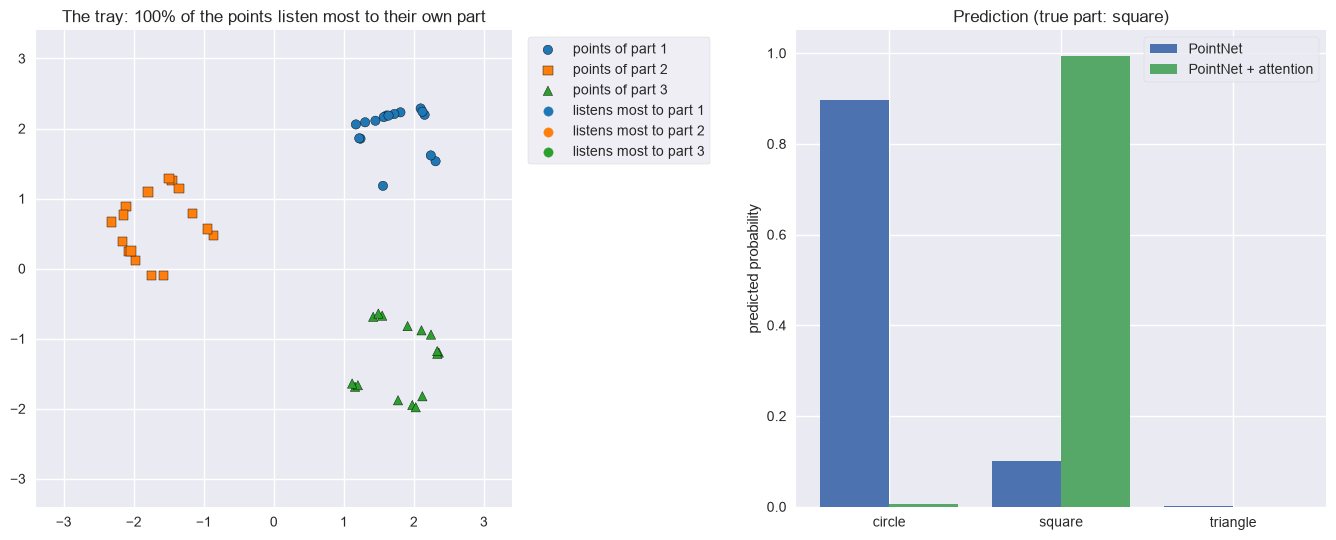

In [113]:
# Optional for Exercise 3: move part 1 of a tray, or take part 3 away, and compare the two trained models.
# The sliders need a running notebook (VS Code or Colab); the book shows the starting state.
# live_figure was defined with the interactive figures in the chapter.
class PointNetWithAttention(nn.Module):
    """The chapter's PointNet with one of the chapter's attention blocks in front of it (as in Exercise 3)."""

    def __init__(self, d_model=32):
        super().__init__()
        self.input_proj = nn.Linear(2, d_model)
        self.attention = SelfAttentionBlock(d_model, dim_feedforward=2 * d_model)
        self.pointnet = PointNetClassifier(input_dim=d_model, widths=(64, 64, 128), num_classes=3, dropout=0.0)

    def forward(self, x, return_attention=False):
        h, A = self.attention(self.input_proj(x))
        logits = self.pointnet(h)
        return (logits, A) if return_attention else logits


tray_states = torch.load("../../data/transformers_trays_models.pt", map_location="cpu")
tray_pointnet = PointNetClassifier(input_dim=2, widths=(64, 64, 128), num_classes=3, dropout=0.0)
tray_pointnet.load_state_dict(tray_states["pointnet"])
tray_attention = PointNetWithAttention()
tray_attention.load_state_dict(tray_states["pointnet_with_attention"])
tray_pointnet.eval()
tray_attention.eval()

widget_tray = 1  # a tray of squares
base_tray = trays["trays_three"][widget_tray]
base_ids = trays["ids_three"][widget_tray]
base_centers = np.array([base_tray[base_ids == part].mean(axis=0) for part in range(3)])
MIN_GAP = 2.2  # parts in the training trays have their centers at least this far apart


def place_part_1(target, keep_part_3):
    """Move the center of part 1 to target, but stop it MIN_GAP away from the other parts, so parts never overlap."""
    center = np.array(target, dtype=float)
    others = [1, 2] if keep_part_3 else [1]
    for _ in range(5):
        for part in others:
            offset = center - base_centers[part]
            distance = np.linalg.norm(offset)
            if distance < MIN_GAP:
                direction = offset / distance if distance > 1e-9 else np.array([1.0, 0.0])
                center = base_centers[part] + MIN_GAP * direction
    return center


def draw_tray(x_part_1, y_part_1, keep_part_3):
    center = place_part_1([x_part_1, y_part_1], keep_part_3)
    points = base_tray.copy()
    points[base_ids == 0] += center - base_centers[0]
    keep = np.ones(len(points), bool) if keep_part_3 else base_ids != 2
    points, ids = points[keep], base_ids[keep]
    x = torch.tensor(points, dtype=torch.float32)[None]
    with torch.no_grad():
        logits, A = tray_attention(x, return_attention=True)
        p_attention = torch.softmax(logits, dim=-1)[0].numpy()
        p_pointnet = torch.softmax(tray_pointnet(x), dim=-1)[0].numpy()
    # The part that gets most of each point's weight
    A_now = A[0].numpy()
    parts_here = np.unique(ids)
    listens_to = parts_here[np.argmax([A_now[:, ids == part].sum(axis=1) for part in parts_here], axis=0)]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw=dict(width_ratios=[1.2, 1]))
    colors = np.array(["tab:blue", "tab:orange", "tab:green"])
    markers = ["o", "s", "^"]
    for part in parts_here:  # marker shape: the part a point belongs to; color: the part it listens to most
        members = ids == part
        axes[0].scatter(*points[members].T, s=45, c=colors[listens_to[members]], marker=markers[part],
                        edgecolors="k", linewidths=0.3, zorder=3, label=f"points of part {part + 1}")
    for part in parts_here:
        axes[0].scatter([], [], c=colors[part], s=45, label=f"listens most to part {part + 1}")
    axes[0].set_xlim(-3.4, 3.4)
    axes[0].set_ylim(-3.4, 3.4)
    axes[0].set_aspect("equal")
    axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)
    moved = np.linalg.norm(center - np.array([x_part_1, y_part_1])) > 1e-6
    axes[0].set_title(f"The tray: {np.mean(listens_to == ids):.0%} of the points listen most to their own part"
                      + ("\n(part 1 stopped next to another part)" if moved else ""))
    xpos = np.arange(3)
    axes[1].bar(xpos - 0.2, p_pointnet, 0.4, label="PointNet")
    axes[1].bar(xpos + 0.2, p_attention, 0.4, label="PointNet + attention")
    axes[1].set_xticks(xpos)
    axes[1].set_xticklabels(part_names)
    axes[1].set_ylim(0, 1.05)
    axes[1].set_ylabel("predicted probability")
    axes[1].set_title(f"Prediction (true part: {part_names[trays['labels_trays_three'][widget_tray]]})")
    axes[1].legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.close(fig)
    return fig


live_figure(draw_tray, dict(
    x_part_1=widgets.FloatSlider(value=round(float(base_centers[0, 0]), 1), min=-2.2, max=2.2, step=0.1,
                                 description="part 1, x", continuous_update=False),
    y_part_1=widgets.FloatSlider(value=round(float(base_centers[0, 1]), 1), min=-2.2, max=2.2, step=0.1,
                                 description="part 1, y", continuous_update=False),
    keep_part_3=widgets.Checkbox(value=True, description="keep part 3"),
))